# Atomic segementation of TEM images using semi-supervised learning.

### Acknowledgements

This tutorial was developed at UVA for STL:

- Kory Burns (koryburns@virginia.edu)

Developed on:
- 14th of July, 2026

In [31]:
import sys
if 'google.colab' in sys.modules:
    local = False
else:
    local = True
print(f"Local environment: {local}")

Local environment: False


## We will use the Package AtomAI as a foundation for this tutorial.

### It's an open-source framework built on PyTorch (i.e., its a wrapper to PyTorch). It bridges instrument-specific parameters in the code to analyze microscopic and spectroscopic data.

In [2]:
# %%capture
if not local:
    !pip install atomai

# import atomai as aoi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 kB 7.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.0/179.0 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.2/291.2 kB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.1/57.1 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 614.2/614.2 kB 44.1 MB/s eta 0:00:00
  Created wheel for mendeleev: filename=mendeleev-0.6.1-py2.py3-none-any.whl size=175053 sha256=46b9e3e825

### Note that we'll install imutils and shapely independently. Imutils gives us different functionalities to handle an image that make portions of this code more seamless. Shapely is an application used acsross GIS, Physics, and Geometry... it alows us to analyze distances between two-dimensional points.

In [3]:
pip install imutils

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for imutils: filename=imutils-0.5.4-py3-none-any.whl size=25870 sha256=414c41705d33b2ed902b1bc8492d4486e404bcd68c2665a9930fafadf512705f
  Stored in directory: /root/.cache/pip/wheels/5b/76/96/ad0c321506837bef578cf3008df3916c23018435a355d9f6b1
Successfully built imutils


In [4]:
pip install shapely

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 50.8 MB/s eta 0:00:00


### Notice there are a wide range of imports we'll need, this is a highly integrated code that depends on so many different libraries.

In [32]:
#@title import
import atomai as aoi
import numpy as np
import matplotlib.pyplot as plt


import torch
import math
import scipy.spatial as spatial
import json
from skimage.transform import resize

from scipy.spatial import cKDTree
from scipy.signal import convolve2d as conv2

from copy import deepcopy as dc
import matplotlib.gridspec as gridspec

import glob
from skimage import color

import time
import random

from PIL import Image
import imutils
# from shapely.geometry import Polygon, MultiPolygon, mapping, shape
from scipy import ndimage
from skimage.draw import polygon
from skimage import color
from skimage import draw

import cv2
from skimage.filters import threshold_minimum, roberts, prewitt, threshold_otsu, unsharp_mask
from skimage.measure import label, regionprops
from skimage.morphology import opening, square, closing

from PIL import Image

import imutils
from shapely.geometry import Polygon, MultiPolygon, mapping, shape

from scipy import ndimage
from scipy import interpolate
from matplotlib.colors import LogNorm
import matplotlib.patches as patches
from matplotlib.patches import Rectangle

### Here lies the functions written.

# Do NOT change ANYTHING unless you know what you are doing.

In [33]:
#@title Functions

def patchify_image(image, FOV_nm, patchsize_nm, plot = False, **kwargs):

    if not (FOV_nm/patchsize_nm) % 1 == 0:
        raise AssertionError("FOV_nm must be exactly divisible by patchsize_nm")

    patches_x, patches_y = int(FOV_nm/patchsize_nm), int(FOV_nm/patchsize_nm)

    patchsize_px = int(image.shape[0]/(patches_x))
    n_patches = int(patches_x*patches_y)
    patches = np.zeros((patches_x,patches_y, patchsize_px, patchsize_px))

    for mm in range(patches_x):
        for nn in range(patches_y):
            patches[mm,nn] = image[int(mm*patchsize_px):int(patchsize_px*mm + patchsize_px),
                                int(nn*patchsize_px):int(patchsize_px*nn + patchsize_px)]

    patches = patches.reshape(n_patches,patchsize_px, patchsize_px)

    if plot:
        fsize = kwargs.get("fsize", 4)
        fig = plt.figure(figsize=(patches_x*fsize, patches_y*fsize))
        gs  = gridspec.GridSpec(patches_x, patches_y, wspace = 0.1, hspace = 0.1)
        for kk in range(n_patches):
            # fig.add_subplot(kk)
            ax = fig.add_subplot(gs[kk])
            ax.imshow(patches[kk], cmap = 'gray')
            ax.set_title(f"patch #{kk}")
            plt.setp(ax, xticks=[], yticks=[])
        # plt.tight_layout()

    return patches

def draw_arrow(axis, arr_start_fraction, arr_end_fraction, **kwargs):

    width_f         = kwargs.get("width_fraction", 0.025)
    color           = kwargs.get("color", "red")
    head_length_f   = kwargs.get("head_length_fraction", 0.05)
    head_width_f    = kwargs.get("head_width_fraction", 0.05)
    alpha           = kwargs.get("alpha", 1)

    xi, xf = axis.get_xlim()
    yi, yf = axis.get_ylim()
    X,Y = abs(xf-xi), abs(yf-yi)

    nominal_size = np.sqrt(X**2 + Y**2 )# X or Y - this should be square. but just in case..
    head_length = head_length_f*nominal_size
    head_width  = head_width_f*nominal_size
    width       = width_f*nominal_size
    X_start = X*arr_start_fraction[0]
    Y_start = Y*arr_start_fraction[1]
    dx = X*(arr_end_fraction[0] - arr_start_fraction[0])
    dy = Y*(arr_end_fraction[1] - arr_start_fraction[1])

    axis.arrow(X_start, Y_start, dx, dy, head_width=head_width, head_length=head_length, length_includes_head=True, color=color, width = width, ec='k', alpha = alpha)

def get_dopant_localenv(dopant_coords, imgdata, FOV_nm, local_window_angstroms = 20, **kwargs):

    px2ang = (FOV_nm*10) / imgdata.shape[0]
    windowsize_px = int(local_window_angstroms / px2ang)
    n_images = len(dopant_coords)

    # markerscale = kwargs.get("markerscale", 1)
    ncols       = kwargs.get("ncols", 5)
    fsize       = kwargs.get("fsize", 4)
    show_marker = kwargs.get("show_marker", True)

    arrow_props = kwargs.get("arrow_props", {"arrow_color" : "yellow",
                                             "arrow_alpha" : 0.5,
                                             "arrow_start_fraction" : [0.4,0.3],
                                             "arrow_end_fraction"   : [0.5,0.5]})

    if "arrow_color" not in arrow_props.keys():
        arrow_props["arrow_color"] = "yellow"
    if "arrow_alpha" not in arrow_props.keys():
        arrow_props["arrow_alpha"] = 0.5
    if "arrow_start_fraction" not in arrow_props.keys():
        arrow_props["arrow_start_fraction"] = [0.4,0.3]
    if "arrow_end_fraction" not in arrow_props.keys():
        arrow_props["arrow_end_fraction"] = [0.5,0.5]
    # arrow_color = kwargs.get("arrow_color", "yellow")
    # arrow_alpha = kwargs.get("arrow_alpha", 0.5)
    # arrow_start_fraction = kwargs.get("arrow_start_fraction", [0.4,0.3])
    # arrow_end_fraction = kwargs.get("arrow_end_fraction", [0.48,0.5])

    nrows = int(np.ceil(n_images/ncols))
    gs = gridspec.GridSpec(nrows, ncols, wspace = 0.03, hspace = 0.25)
    fig = plt.figure(figsize=(fsize*ncols,fsize*nrows))

    # markersize = (1/windowsize_px)**0.75 * 10000 * markerscale

    dopant_local_ims = aoi.utils.extract_subimages(imgdata, dopant_coords[:,:2], window_size=windowsize_px)[0].squeeze()
    if dopant_local_ims.ndim == 2:
        dopant_local_ims = dopant_local_ims[None,:,:]

    if len(dopant_local_ims) != n_images:
        print("Warning!\n some image patches are missing because window_size is too large!")
    c1 = c2 = dopant_local_ims.shape[1]/2
    for ii in range(len(dopant_local_ims)):
        ax = fig.add_subplot(gs[ii])
        ax.imshow(dopant_local_ims[ii], cmap = 'gray')
        if show_marker:
            # ax.scatter(c1,c2,c='None',s=markersize, ec='darkorange', alpha = 0.75, lw=1, ls='--')
            draw_arrow(ax, arrow_props['arrow_start_fraction'], arrow_props['arrow_end_fraction'], color = arrow_props['arrow_color'], alpha = arrow_props['arrow_alpha'])
        ax.set_title(f"Coordinate #{ii+1:02d}")
        plt.setp(ax,xticks=[],yticks=[])

    return dopant_local_ims

def do_GMM_split(coordinates, imgdata, FOV_nm, windowsize_angstrom = 3, num_comps = 3, plot = True):

    FOV_ang = FOV_nm*10
    windowsize_px = int((windowsize_angstrom/FOV_ang)*imgdata.shape[0]) # Convert from angstrom to pixels
    print("window size is: {} px".format(windowsize_px))

    # time1 = time.time()
    separation_01 = aoi.stat.update_classes(coordinates,
                                            imgdata,
                                            method="gmm_local",
                                            n_components = num_comps,
                                            window_size = windowsize_px,
                                            )
    classes     = {}
    ints        = {}
    mean_images = {}

    for mm in range(num_comps):
        classes[mm]     =  np.argwhere(separation_01[0][:,2]==mm).squeeze()
        ints[mm]        =  aoi.utils.get_intensities_(separation_01[0][classes[mm]], imgdata, r=5)
        mean_images[mm] = np.mean(aoi.utils.extract_subimages(imgdata, separation_01[0][classes[mm]][:,:2], window_size=windowsize_px)[0].squeeze(), axis=0)

    if plot:
        ncols = 4
        fsize = 4
        num_images = len(classes)
        nrows = int(np.ceil(num_images/ncols))
        gs = gridspec.GridSpec(nrows, ncols, wspace = 0.03, hspace = 0.25)
        fig = plt.figure(figsize=(fsize*ncols,fsize*nrows))
        for ii in range(len(classes)):
            ax = fig.add_subplot(gs[ii])
            ax.imshow(mean_images[ii], cmap = 'seismic')
            ax.set_title(f"Class {int(ii+1)}\n {len(separation_01[0][classes[ii]])} members", fontsize = 16)
            plt.setp(ax,xticks=[],yticks=[])

    return separation_01, classes, ints, mean_images

def img_transform(img, FOV_nm, px2ang, powerfactor):

    resize_dim = int(FOV_nm*10/px2ang)
    imgdata_r = aoi.utils.cv_resize(img, (resize_dim, resize_dim))

    return normalize((imgdata_r - imgdata_r.min())**powerfactor)

def decoded_squeeze(decoded_img, num_classes):

    decoded = decoded_img.squeeze()

    if num_classes > 1:
        class_thresh = 0.5  # Should be about 50% or higher for that class... Actually 50% seems to be about the best for imaging this. (both lower AND higher is not so great)
        clengths = []
        for ch in range(decoded.shape[-1]):
            clengths.append(len(np.where(decoded[:,:,ch] > class_thresh)[1]))
        clengths = np.asarray(clengths)
        background_ch = clengths.argmax()  # We assume that MOST pixels are background, which should be a valid assumption.

        decoded_ = np.zeros(decoded.shape[:-1])
        for ch in range(decoded.shape[-1]):
            if not ch == background_ch:
                decoded_ += decoded[..., ch] * (ch+1)
        decoded = decoded_

    else: pass

    return decoded

def virtual_annular(r1,r2,data4Din,**kwargs):

  offset = kwargs.get("offset", [0,0])

  d1,d2,d3,d4 = data4Din.shape
  virtualimg = np.zeros((d1,d2))

  mask = np.zeros_like(data4Din[0,0])
  c1,c2 = int(data4Din[0,0].shape[0]/2), int(data4Din[0,0].shape[1]/2)
  c1 += offset[0]
  c2 += offset[1]
  rr1,cc1 = draw.disk((c1,c2),r1,shape = data4Din[0,0].shape)
  rr2,cc2 = draw.disk((c1,c2),r2,shape = data4Din[0,0].shape)
  mask[rr2,cc2] = 1
  mask[rr1,cc1] = 0

  for ii in range(virtualimg.shape[0]):
    for jj in range(virtualimg.shape[1]):
      virtualimg[ii,jj] = np.sum(mask*data4Din[ii,jj])

  return virtualimg, mask

def plotStrain(strain):
  plt.figure(figsize=(16,7))
  gs = gridspec.GridSpec(2,6, width_ratios = [1,1,1,0.075,1,0.075])
  aximg = plt.subplot(gs[0:2,0:2])
  ax00,cax00,ax01,cax01 = plt.subplot(gs[0,2]), plt.subplot(gs[0,3]), plt.subplot(gs[0,4]), plt.subplot(gs[0,5])
  ax10,cax10,ax11,cax11 = plt.subplot(gs[1,2]), plt.subplot(gs[1,3]), plt.subplot(gs[1,4]), plt.subplot(gs[1,5])

  img,scale = NBEDimage[k], NBEDimscale[k]
  aximg.imshow(img, cmap = 'gray')

  d1,d2 = img.shape
  origin = (0.03*d1, 0.9*d2)
  FOV = scale*d1
  barlength = d1/4
  length = barlength*scale
  height = barlength/10
  aximg.add_patch(patches.Rectangle((origin),barlength, height, color = 'w', ec='k'))
  tx,ty = origin[0]+barlength/2, origin[1]-height*0.5
  aximg.annotate("{} nm".format(length), (tx,ty), ha = 'center', fontsize = 20, color = 'k', weight = 'bold')

  im00 = ax00.imshow(strain[0], cmap = 'RdBu')
  im01 = ax01.imshow(strain[1], cmap = 'RdBu')
  im10 = ax10.imshow(strain[2], cmap = 'RdBu')
  im11 = ax11.imshow(strain[3], cmap = 'RdBu')

  cbar00 = plt.colorbar(im00, ax=cax00, aspect = 10, fraction = 3, format="%.2f")
  cbar01 = plt.colorbar(im01, ax=cax01, aspect = 10, fraction = 3, format="%.2f")
  cbar10 = plt.colorbar(im10, ax=cax10, aspect = 10, fraction = 3, format="%.2f")
  cbar11 = plt.colorbar(im11, ax=cax11, aspect = 10, fraction = 3, format="%.2f")

  cbar00.ax.tick_params(labelsize = 15, width = 3, length = 5)
  cbar01.ax.tick_params(labelsize = 15, width = 3, length = 5)
  cbar10.ax.tick_params(labelsize = 15, width = 3, length = 5)
  cbar11.ax.tick_params(labelsize = 15, width = 3, length = 5)

  ax00.set_title("e$_{xx}$ strain")
  ax01.set_title("e$_{xy}$ strain")
  ax10.set_title(r"e$_\theta$ strain")
  ax11.set_title("e$_{yy}$ strain")
  axes = [aximg, ax00, ax01, ax10, ax11, cax00, cax01, cax10, cax11]
  for ax in axes:
    ax.axis('off')

def plotDPC():
  fig = plt.figure(figsize = (18,7))
  gs = gridspec.GridSpec(2,5)
  ax1 = plt.subplot(gs[0:2, 0:2])
  ax12,ax13,ax14 = plt.subplot(gs[0,2]), plt.subplot(gs[0,3]), plt.subplot(gs[0,4])
  ax22,ax23,ax24 = plt.subplot(gs[1,2]), plt.subplot(gs[1,3]), plt.subplot(gs[1,4])

  ax1.imshow(img, cmap = 'gray')
  d1,d2 = img.shape
  origin = (0.03*d1, 0.9*d2)
  FOV = scale*d1
  barlength = d1/4
  length = barlength*scale
  height = barlength/10
  ax1.add_patch(patches.Rectangle((origin),barlength, height, color = 'w', ec='k'))
  tx,ty = origin[0]+barlength/2, origin[1]-height*0.5
  ax1.annotate("{} nm".format(length), (tx,ty), ha = 'center', fontsize = 20, color = 'k', weight = 'bold')

  ax12.imshow(com_x, cmap = 'magma')
  ax13.imshow(com_y, cmap = 'magma')
  ax14.imshow(angle, cmap = 'RdBu')

  ax22.imshow(com_mag, cmap = 'magma')
  ax23.imshow(charge_rel, cmap = 'RdBu')
  ax24.imshow(phase, cmap = 'RdBu')

  ax12.set_title("CoM x")
  ax13.set_title("CoM y")
  ax14.set_title("CoM angle")
  ax22.set_title("CoM magnitude")
  ax23.set_title("relative charge")
  ax24.set_title("relative potential")

  axes = [ax1,ax12,ax13,ax14,ax22,ax23,ax24]
  for ax in axes:
    ax.axis('off')

def COM_full(nysamp, nxsamp, nypix, nxpix, duin, dvin,CBED_in):
    from scipy import ndimage
    import math

    com_mag = np.zeros((nysamp, nxsamp))
    com_y = np.zeros((nysamp, nxsamp))
    com_x = np.zeros((nysamp, nxsamp))
    angle = np.zeros((nysamp, nxsamp))
    xyzero = np.zeros(2)
    xyzero = ndimage.measurements.center_of_mass(np.mean(CBED_in, axis=(0,1)) )
#    xyzero[0] = nypix/2
#    xyzero[1] = nxpix/2

    for y in range(nysamp):
        for x in range(nxsamp):
            xycbed = ndimage.measurements.center_of_mass(CBED_in[y,x,:,:])
            com_x[y,x] = (xycbed[1]-xyzero[1])*duin
            com_y[y,x] = (xycbed[0]-xyzero[0])*dvin
            com_mag[y,x] = math.sqrt(com_y[y,x]*com_y[y,x]+com_x[y,x]*com_x[y,x])

    angle = np.arctan2(com_y,com_x)

    return com_y, com_x, angle, com_mag

def align_stack(stack, blur, style = "crop", **kwargs):
  '''
  Aligns a stack of 2D images by cross correlation between each subsequent frame
  In computing the cross correlation between two images, for periodic images,
  it helps to blur each of the images to pick up non-periodic features more easily.
  The final drift corrected image stack will have "dead" cols/rows where pixels are not aligned.
  This can be handled via the style option: Use "crop", "zero", or "none"
  '''
  plot = kwargs.get("plot", "True")
  cmap = kwargs.get("cmap", "gray")


  drift_XY = np.zeros((len(stack), 2), dtype = int)

  ## Get the frame-to-frame drift:
  for ii in range(len(drift_XY)-1):
    if blur == None:
      drift_XY[ii+1] = cross_image(stack[ii], stack[ii+1])
    else:
      drift_XY[ii+1] = cross_image(ndimage.gaussian_filter(stack[ii], sigma = blur), ndimage.gaussian_filter(stack[ii+1], sigma = blur))

  # Add each previous frame's drift to the following frame:
  for ii in range(len(drift_XY)-1):
    drift_XY[ii+1] = drift_XY[ii] + drift_XY[ii+1]

  summed_images = np.zeros((stack.shape[0] - 1, stack.shape[1], stack.shape[2]))
  for ii in range(len(drift_XY)-1):
    summed_images[ii] = np.roll(stack[ii], drift_XY[ii], axis=(0,1)) + np.roll(stack[ii+1], drift_XY[ii], axis=(0,1))
  summed_image = normalize(np.sum(summed_images, axis=0))


  if style == "zero":
    if drift_XY[-1][1] >= 0:
        summed_image[:drift_XY[-1][1], :] = 0
    else:
        summed_image[drift_XY[-1][1]:, :] = 0
    if drift_XY[-1][0] >= 0:
        summed_image[:, :drift_XY[-1][0]] = 0
    else:
        summed_image[:, drift_XY[-1][0]:] = 0

  elif style == "crop":
    if drift_XY[-1][1] >= 0:
        summed_image = summed_image[drift_XY[-1][1]:, :]
    else:
        summed_image = summed_image[:drift_XY[-1][1], :]
    if drift_XY[-1][0] >= 0:
        summed_image = summed_image[:, drift_XY[-1][0]:]
    else:
        summed_image = summed_image[:, :drift_XY[-1][0]]

  elif style == "none":
    pass
  else:
    raise NotImplementedError('Please choose "crop", "zero", "none" as Style')

  if plot:
    plt.figure(figsize=(6,6))
    plt.imshow(summed_image, cmap = cmap)

  return summed_image, drift_XY


from sklearn.decomposition import NMF
def compute_NMF(specim, eax, N, plot = True):
  specimflat = np.reshape(specim, (specim.shape[0]*specim.shape[1],specim.shape[2]))
  SIdecon=np.copy(specimflat)
  SIdecon=np.copy(specimflat[:,:])
  SIdecon[np.where(SIdecon<0)]=0
  XY = specim.shape[0:2]

  model=NMF(n_components=N, random_state = 42)
  NMFIm=model.fit_transform(SIdecon[:,:])
  NMFSpec=model.components_
  NMFIm=NMFIm.reshape(XY+(N,)).transpose(2,0,1)

  if plot:
    rows = int(np.ceil(float(N)/3))
    cols = int(np.ceil(float(N)/rows))

    fig1,ax1 = plt.subplots(figsize = (10,4))

    for jj in range(N):
        try:
          ax1.plot(eax[:],NMFSpec[jj],color = colorlist[jj], label = jj+1)
        except IndexError:
          rollover = int(jj/len(colorlist))
          ax1.plot(eax[:],NMFSpec[jj],color = colorlist[int(jj - len(colorlist)*rollover)], label = jj+1)
        ax1.grid(True)
        ax1.tick_params(labelsize=10)
        ax1.legend()
    plt.show()
    gs2 = gridspec.GridSpec(rows, cols)
    fig2 = plt.figure(figsize = (5*cols, 4*(1+rows//2)))
    for jj in range(N):
        ax2 = fig2.add_subplot(gs2[jj])
        try:
          ax2.imshow(NMFIm[jj],cmap = Cmap_list[jj])
        except IndexError:
          rollover = int(jj/len(colorlist))
          ax2.imshow(NMFIm[jj],cmap = Cmap_list[int(jj - len(colorlist)*rollover)])
        ax2.set_title('Component ' + str(jj+1))
        plt.setp([ax2],xticks=[], yticks=[])

  return NMFIm, NMFSpec


def survey_images(imagelist, scalelist, scalebar = (1/8), **kwargs):
    ncols = kwargs.get("ncols", 3)
    fsize = kwargs.get("fsize", 8)

    num_im = len(imagelist)
    gs = gridspec.GridSpec(1, ncols, wspace = 0.03, hspace = 0.01)
    for kk in range(int(num_im/ncols)):
        fig = plt.figure(figsize=(fsize*ncols,fsize))
        for ii, image in enumerate(imagelist[int(kk*ncols):int(ncols*kk+ncols)]):
            ax = fig.add_subplot(gs[ii])
            ax.imshow(image, cmap = 'gray')
            actual_length = plot_scalebar(ax, image, scalelist[int(ncols*kk + ii)], 0.125, dist_from_corner = 2, scalebar_style = 'percent')
            ax.set_title(f"Scalebar: {actual_length} nm")
            plt.setp(ax,xticks=[],yticks=[])

def plot_scalebar(axis, image, pixelsize_m, length_nm, dist_from_corner, **kwargs):

    ratio    = kwargs.get("ratio", 6)
    scalebar_style = kwargs.get("scalebar_style", "fixed") # fixed or percent
    sblength = length_nm/pixelsize_m
    sbheight = sblength/ratio
    d1,d2 = image.shape
    dist_from_corner = (dist_from_corner*d1)/100

    if scalebar_style == 'percent':
        sblength = (length_nm * d1)
        sbheight = sblength/ratio
        actual_length = sblength*pixelsize_m
    else:
        actual_length = length_nm
    o1,o2 = d2 - dist_from_corner - sblength, d1-dist_from_corner-sbheight
    axis.add_patch(patches.Rectangle((o1,o2),sblength, sbheight, color = 'w', ec='k'))
    # print(f"scalebar length: {actual_length} nm")

    return actual_length

def move_subplot(axis, xdistance=0, ydistance=0):
    box = axis.get_position()
    box.x0 = box.x0 + xdistance
    box.x1 = box.x1 + xdistance
    box.y0 = box.y0 + ydistance
    box.y1 = box.y1 + ydistance
    axis.set_position(box)

def cross_image(image1, image2, upscale = 1):
	"""
	Determines the shift in pixels from image1 to image2.
	Assumes image1 and image2 size are the same
	For subpixel precision, consider changing upscale > 1,
	for example, 4x larger image comparison. Warning, this is not tested
	"""
	d1,d2 = image1.shape
	if upscale == 1:
		image1FFT = np.fft.fft2(image1)
		image2FFT = np.conjugate(np.fft.fft2(image2))
		imageCCor = np.real(np.fft.ifft2((image1FFT * image2FFT)))
		imageCCorShift = np.fft.fftshift(imageCCor)
		row, col = image1.shape
		yShift, xShift = np.unravel_index(np.argmax(imageCCorShift), (row, col))
		yShift -= int(row / 2)
		xShift -= int(col / 2)
	else:
		image1_, image2_ = resize(image1, (d1*upscale, d2*upscale)), resize(image2, (d1*upscale, d2*upscale))
		image1FFT = np.fft.fft2(image1_)
		image2FFT = np.conjugate(np.fft.fft2(image2_))
		imageCCor = np.real(np.fft.ifft2((image1FFT * image2FFT)))
		imageCCorShift = np.fft.fftshift(imageCCor)
		row, col = image1_.shape
		yShift, xShift = np.unravel_index(np.argmax(imageCCorShift), (row, col))
		yShift -= int(row / 2)
		xShift -= int(col / 2)
		yShift /= upscale
		xShift /= upscale
	return yShift, xShift

def plotDPC():
  fig = plt.figure(figsize = (18,7))
  gs = gridspec.GridSpec(2,5)
  ax1 = plt.subplot(gs[0:2, 0:2])
  ax12,ax13,ax14 = plt.subplot(gs[0,2]), plt.subplot(gs[0,3]), plt.subplot(gs[0,4])
  ax22,ax23,ax24 = plt.subplot(gs[1,2]), plt.subplot(gs[1,3]), plt.subplot(gs[1,4])

  ax1.imshow(img, cmap = 'gray')
  d1,d2 = img.shape
  origin = (0.03*d1, 0.9*d2)
  FOV = scale*d1
  barlength = d1/4
  length = barlength*scale
  height = barlength/10
  ax1.add_patch(patches.Rectangle((origin),barlength, height, color = 'w', ec='k'))
  tx,ty = origin[0]+barlength/2, origin[1]-height*0.5
  ax1.annotate("{} nm".format(length), (tx,ty), ha = 'center', fontsize = 20, color = 'k', weight = 'bold')

  ax12.imshow(com_x, cmap = 'magma')
  ax13.imshow(com_y, cmap = 'magma')
  ax14.imshow(angle, cmap = 'RdBu')

  ax22.imshow(com_mag, cmap = 'magma')
  ax23.imshow(charge_rel, cmap = 'RdBu')
  ax24.imshow(phase, cmap = 'RdBu')

  ax12.set_title("CoM x")
  ax13.set_title("CoM y")
  ax14.set_title("CoM angle")
  ax22.set_title("CoM magnitude")
  ax23.set_title("relative charge")
  ax24.set_title("relative potential")

  axes = [ax1,ax12,ax13,ax14,ax22,ax23,ax24]
  for ax in axes:
    ax.axis('off')

def CalibrateSI2(EAx,SI,num_spectral_px,extrapolate = False):
    m,M = np.amax(np.amin(EAx)), np.amin(np.amax(EAx))
    try:
      Eout=np.linspace(m,M,num_spectral_px)[1:]
      Eout=np.linspace(m,M,num_spectral_px,endpoint=True)
    except ValueError:
      Eout=np.linspace(m,M,5000)[1:]
      Eout=np.linspace(m,M,5000,endpoint=True)
    if extrapolate:
        SIout=np.array([[interpolate.interp1d(e,s,fill_value="extrapolate")(Eout) for e,s in zip(erow,srow)] for erow,srow in zip(EAx,SI)])
    else:
        SIout=np.array([[interpolate.interp1d(e,s)(Eout) for e,s in zip(erow,srow)] for erow,srow in zip(EAx,SI)])
    return Eout,SIout

def normalize(image, scale = 1):
    # scale = 1 or 255 for now.
    return scale*(image-np.min(image))/np.ptp(image)

def get_neighbormean(imgarr,coordinate):
  a1,a2,_ = coordinate
  all_c = np.zeros((3**2,2)).astype(int)
  all_c[0,:] = a1-1,a2+1
  all_c[1,:] = a1,  a2+1
  all_c[2,:] = a1+1,a2+1
  all_c[3,:] = a1-1,a2
  all_c[4,:] = a1,a2
  all_c[5,:] = a1+1,a2
  all_c[6,:] = a1-1,a2-1
  all_c[7,:] = a1,a2-1
  all_c[8,:] = a1+1,a2-1

  imgarr = normalize(imgarr)
  ints = []
  for cc in all_c:
    ints.append(imgarr[cc[0],cc[1]])
  ints = np.asarray(ints)

  return np.mean(ints)

def normalize_individually(stack, scale = 1):
    # scale = 1 or 255 for now
    normalized_stack = np.copy(stack)
    for ii in range(len(stack)):
        normalized_stack[ii] = normalize(stack[ii], scale)
    return normalized_stack

def LoadMovie(filename):
    mov    = np.load(filename)
    movj = json.load(open(filename[:-3]+'json','r'))
    mov_scale = movj['spatial_calibrations'][1]['scale']
    return mov, mov_scale

def ready_images(images, FOV, resizefactor, powerfactor):
  newsize = int(FOV*10/resizefactor)

  if images.ndim == 2:
    newimages = np.zeros((newsize, newsize))
    imgdata = aoi.utils.cv_resize(images, (newsize, newsize))
    newimages = normalize((imgdata - imgdata.min())**powerfactor)

  elif images.ndim == 3:
    newimages = np.zeros((len(images), newsize, newsize))
    for ii,image in enumerate(images):
      imgdata = aoi.utils.cv_resize(image, (newsize, newsize))
      newimages[ii] = normalize((imgdata - imgdata.min())**powerfactor)

  return newimages



from IPython.core.display import Video
!pip install imageio-ffmpeg
import imageio

# To stop warning logs during movie creation
import imageio.core.util
def silence_imageio_warning(*args, **kwargs):
    pass

imageio.core.util._precision_warn = silence_imageio_warning


#@title Functions (moar)


def CalibrateEnergyAxis(SI,disp,style='fwhm',subfitwidth=8):
    Einit=np.arange(0,SI.shape[2])*disp
    if style=='pixel': ZLPC=np.array([[Einit[np.argmax(s)] for s in row] for row in SI])
    if style=='fwhm':
        lh,uh=[],[]
        avspec=np.average(SI,axis=(0,1))
        for row in SI:
            lh.append([]);uh.append([])
            for s in row:
                if np.amax(s)<1000: # This line is for thick samples when ZLP drops to noise levels
                    s=avspec
                lh[-1].append(Einit[np.argmin(np.abs(s[:np.argmax(s)]/np.amax(s)-0.5))])
                uh[-1].append(Einit[np.argmin(np.abs(s[np.argmax(s):]/np.amax(s)-0.5))+np.argmax(s)])
        lh=np.asarray(lh)
        uh=np.asarray(uh)
        ZLPC=np.average([uh,lh],axis=0)
    if style=='subpixel':
        def gauss(x,a,x0,s): return a*np.exp(-(x-x0)**2/s**2)
        from scipy.optimize import curve_fit
        ZLPC=np.array([[curve_fit(gauss,Einit[np.argmax(s)-W:np.argmax(s)+W],
                               s[np.argmax(s)-W:np.argmax(s)+W]/np.amax(s))[0][1] for s in row] for row in SI])
    return np.array([[Einit-c for c in row] for row in ZLPC])

def CalibrateSI(EAx,SI,num_spectral_px):
    m,M = np.amax(np.amin(EAx,axis=(2))), np.amin(np.amax(EAx,axis=(2)))
    try:
      Eout=np.linspace(m,M,num_spectral_px)[1:]
      Eout=np.linspace(m,M,num_spectral_px,endpoint=True)
    except ValueError:
      Eout=np.linspace(m,M,5000)[1:]
      Eout=np.linspace(m,M,5000,endpoint=True)
    SIout=np.array([[interpolate.interp1d(e,s)(Eout) for e,s in zip(erow,srow)] for erow,srow in zip(EAx,SI)])
    return Eout,SIout


def RemoveBackgroundSI_THICK(E,S,fst,fen, threshold = 5000):
    ist=np.argmin(np.abs(E-fst));ien=np.argmin(np.abs(E-fen))
    f=interpolate.interp1d(E[ist:ien],S[ist:ien],kind='linear')
    elog=np.log(E[ist:ien][np.where(S[ist:ien]>0)])
    slog=np.log(S[ist:ien][np.where(S[ist:ien]>0)])
    if len(np.where(S[ist:ien]>0)[0]) == 0.:
        plt.plot(E[ist:],S[ist:])
        return E[ist:],np.zeros(E[ist:].shape)
    if np.max(S) > threshold:
      r,A0=np.polyfit(elog,slog,1)
      return E[ist:],S[ist:]-np.exp(A0)*E[ist:]**(r),
    else:
      print("Too thick sir or ma'am")
      return E[ist:],S[ist:]

def RemoveBackgroundSI2R(E,S,fs1,fe1,fs2,fe2):
    is1=np.argmin(np.abs(E-fs1));ie1=np.argmin(np.abs(E-fe1))
    is2=np.argmin(np.abs(E-fs2));ie2=np.argmin(np.abs(E-fe2))
    e,s=np.append(E[is1:ie1],E[is2:ie2]),np.append(S[is1:ie1],S[is2:ie2])
    elog=np.log(e[np.where(s>0)])
    slog=np.log(s[np.where(s>0)])
    r,A0=np.polyfit(elog,slog,1)
    return E[is1:],S[is1:]-np.exp(A0)*E[is1:]**(r)

def RemoveBackgroundSI2R_THICK(E,S,fs1,fe1,fs2,fe2, threshold = 5000):
    is1=np.argmin(np.abs(E-fs1));ie1=np.argmin(np.abs(E-fe1))
    is2=np.argmin(np.abs(E-fs2));ie2=np.argmin(np.abs(E-fe2))
    e,s=np.append(E[is1:ie1],E[is2:ie2]),np.append(S[is1:ie1],S[is2:ie2])
    if np.max(S)>threshold:
      elog=np.log(e[np.where(s>0)])
      slog=np.log(s[np.where(s>0)])
      r,A0=np.polyfit(elog,slog,1)
      return E[is1:],S[is1:]-np.exp(A0)*E[is1:]**(r)
    else:
      print('too thick? Consider adjusting threshold')
      return E[is1:], S[is1:]

def FitPowerlaw_THICK(E,S,fst,fen, threshold = 5000):
    ist=np.argmin(np.abs(E-fst));ien=np.argmin(np.abs(E-fen))
    #e,s=np.append(E[is1:ie1],E[is2:ie2]),np.append(S[is1:ie1],S[is2:ie2])

    if np.max(S) > threshold:
      fig=plt.figure(figsize=(20,3))

      ax=fig.add_subplot(131)

      plt.plot(E,S,color='k',label='Data')
      plt.axvspan(E[ist],E[ien], color = 'r', alpha = 0.6, label = 'Fit Region')
      # plt.plot(E[ist:ien],S[ist:ien],marker='o',ms=7,markerfacecolor='none',markeredgecolor='r',lw=0,label='Fit Region')
      plt.legend(frameon=False,fontsize=13)
      fite=np.linspace(E[ist+1],E[ien-1],1000)
      f=interpolate.interp1d(E[ist:ien],S[ist:ien],kind='linear')
      elog=np.log(E[ist:ien][np.where(S[ist:ien]>0)])
      slog=np.log(S[ist:ien][np.where(S[ist:ien]>0)])
      # plt.ylim(0,0.002)
      r,A0=np.polyfit(elog,slog,1)

      ax=fig.add_subplot(132)

      plt.plot(E[ist:],S[ist:],color='k',label='Data')
      plt.plot(E[ist:],np.exp(A0)*E[ist:]**(r),'b',lw=3,label='Power Law Fit')
      plt.tick_params(labelsize=16)
      plt.legend(frameon=False,fontsize=13)

      ax=fig.add_subplot(133)

      plt.axhline(0,color='k')
      plt.plot(E[ist:],S[ist:]-np.exp(A0)*E[ist:]**(r),color='b',label='Powerlaw Subtraction')
      plt.tick_params(labelsize=16)
      ax.set_xlabel(r'Energy Loss ($eV$)',fontsize=16)
      plt.subplots_adjust(top=1,bottom=0.06,right=1,left=0.15)
      plt.legend(frameon=False,fontsize=10,labelspacing=0.3,handlelength=1,handletextpad=0.2)
      # plt.ylim(-0.0001,0.001)

      return E[ist:],S[ist:]-np.exp(A0)*E[ist:]**(r)

    else: # if max signal is <5000 counts, too thick for fitting
      S = S # Then don't perform any fitting, leave pixel as-is
      fig=plt.figure(figsize=(8,5))
      ax=fig.add_subplot(131)
      plt.plot(E*1000,S,color='k',label='Data')
      plt.title("Too thick for fitting")

      return E[ist:],S[ist:]

def FitPowerlaw2R_THICK(E,S,fs1,fe1,fs2,fe2, threshold = 5000, plot = True):
    is1=np.argmin(np.abs(E-fs1));ie1=np.argmin(np.abs(E-fe1))
    is2=np.argmin(np.abs(E-fs2));ie2=np.argmin(np.abs(E-fe2))

    if np.max(S) > threshold:
      S = S/np.amax(S)
      e,s=np.append(E[is1:ie1],E[is2:ie2]),np.append(S[is1:ie1],S[is2:ie2])
      if plot:

        fig=plt.figure(figsize=(20,3))
        ax=fig.add_subplot(131)

        plt.plot(E,S,color='k',label='Data')
        plt.axvspan(E[is1],E[ie1], color = 'r', alpha = 0.6, label = 'Fit Region 1')
        plt.axvspan(E[is2],E[ie2], color = 'b', alpha = 0.6, label = 'Fit Region 2')
        # plt.plot(e*1000,s,marker='o',ms=7,markerfacecolor='none',markeredgecolor='r',lw=0,label='Fit Region')
        plt.legend(frameon=False,fontsize=13)
      else:
        pass
      fite=np.linspace(E[is1+1],E[ie2-1],300)
      f=interpolate.interp1d(E[is1:ie2],S[is1:ie2],kind='linear')
      nozeros=s[np.where(s>0)]
      nozeroe=e[np.where(s>0)]
      elog=np.log(nozeroe)
      slog=np.log(nozeros)
      # plt.ylim(0,0.02)
      r,A0=np.polyfit(elog,slog,1)

      if plot:
        ax=fig.add_subplot(132)

        plt.plot(E[is1:],S[is1:],color='k',label='Data')
        plt.plot(E[is1:],np.exp(A0)*E[is1:]**(r),'b',label='Power Law Fit')
        plt.tick_params(labelsize=16)
        plt.legend(frameon=False,fontsize=13)

        ax=fig.add_subplot(133)

      # plt.plot(fite,f(fite)-np.exp(a*fite**3+b*fite**2+c*fite+d),color='r',label='Exponential Subtraction')
        plt.plot(E[is1:],S[is1:]-np.exp(A0)*E[is1:]**(r),color='b',label='Powerlaw Subtraction')
        plt.tick_params(labelsize=16)
        ax.set_xlabel(r'Energy Loss ($eV$)',fontsize=16)
        plt.subplots_adjust(top=1,bottom=0.06,right=1,left=0.15)
        plt.axhline(0,color='k')
        plt.legend(frameon=False,fontsize=10,labelspacing=0.3,handlelength=1,handletextpad=0.2)

      # plt.ylim(-0.001,0.001)

      return E[is1:],S[is1:]-np.exp(A0)*E[is1:]**(r)

    else: # if max signal is <5000 counts, too thick for fitting
      S = S # Then don't perform any fitting, leave pixel as-is
      fig=plt.figure(figsize=(20,3))
      ax=fig.add_subplot(131)
      plt.plot(E*1000,S,color='k',label='Data')
      plt.title("Too thick for fitting")

      return E[is1:],S[is1:]  # Still return with the truncated energy and spectra, to align with the rest


* I have several functions here that assign a CLASS to an atom.
* for example, our first model starts with only providing coordinates (no classification)
* Then we need to label different classes. Rather than doing this manually, do it with some utility functions

In [7]:
#@title MoS2 classify function(s)

def MoS2_split_all(coordinates, imgdata, FOV_nm,
                   SVL_angstroms, NW_angstroms, A_site_intensity, A_site_sub, S_intensity,
                   **kwargs):
    # these "variables" are the ones that might actually require adjusting
    # A_site_sub            = kwargs.get("A_site_sub", "bright") # "bright" or "dim"
    # A_site_thresh         = 0.6
    # SVL_angstroms         = 2.7   # for SVL detection
    # NW_thresh_angstroms   = 5     # for NW vs contamination detection (distance)

    # these "variables" probably should be locked in
    plot                  = kwargs.get("plot", True)
    merge_threshold       = kwargs.get("merge_threshold", 0.025)  # 0.025 usually... just using 0.07 for debugging
    ncomps                = kwargs.get("ncomps", 3)
    winsize_angstrom      = kwargs.get("winsize_angstrom", 3)

    # these kwargs are for removal of contamination only
    filter_contamination  = kwargs.get("filter_contamination", False)
    blur_angstroms        = kwargs.get("blur_angstroms", 1)
    scaling_factor        = kwargs.get("scaling_factor", 0.3)
    plot_contam_filtered  = kwargs.get("plot_contam_filtered", True)

    px2ang = imgdata.shape[0]/(FOV_nm*10)




    #### Where to put this remove contamination step?!?!?!
    #Not in the beginning?
    #Maybe only use for Mo sites? or S2?


    # if filter_contamination:
    #     imgdata = remove_contamination(imgdata, FOV_nm, px2ang, blur_angstroms = blur_angstroms, scaling_factor = scaling_factor, plot = plot_contam_filtered)

    updatedcoords, classes, _, _ = do_GMM_split(coordinates, imgdata, FOV_nm,    # Back to using the raw image data.
                                                    windowsize_angstrom = winsize_angstrom,
                                                    num_comps = ncomps,
                                                    plot = plot)

      #     # if contamination_present:

#     #     scaling_factor = kwargs.get("scaling_factor", 0.3)
#     #     blur_angstroms = kwargs.get("blur_angstroms", 1)
#     #     scaling = scaling_factor*(FOV_nm/16)
#     #     px2ang = FOV_nm/imgdata.shape[0]
#     #     blur_pixels = blur_angstroms/px2ang

#     #     imgdata_b = normalize(ndimage.gaussian_filter(imgdata, sigma = blur_pixels))
#     #     imgdata_f = normalize((imgdata - scaling*imgdata_b))
#     # else:
#     #     imgdata_f = imgdata


    # Then take average of each classes intensity BUT USING THE IMAGEDATA!
    classes,ints = {},{}
    for mm in range(ncomps):
        classes[mm]     =  np.argwhere(updatedcoords[0][:,2]==mm).squeeze()
        ints[mm]        =  aoi.utils.get_intensities_(updatedcoords[0][classes[mm]], imgdata, r=5)

    intensity_means = []
    for _ , vals in ints.items():
        intensity_means.append(vals.mean())
    intensity_means = np.asarray(intensity_means)
    cs = {}
    for kk in range(ncomps):
        cs[kk] = updatedcoords[0][updatedcoords[0][:,2] == kk]

    # differences
    if ncomps == 3:
        c01 = abs(intensity_means[0]-intensity_means[1])
        c02 = abs(intensity_means[0]-intensity_means[2])
        c12 = abs(intensity_means[1]-intensity_means[2])
        print(f"class mean differences: c01: {c01}, c02: {c02}, c12: {c12}")

        if c01 <= merge_threshold: # then we merge these two classes
            print("Merging 0 and 1")
            merged_c01 = np.concatenate((cs[0], cs[1]), axis=0)
            if intensity_means[0] > intensity_means[2]:
                Mo_, S_, NW_ = merged_c01, cs[2], np.empty((0,3))
            else:
                Mo_, S_, NW_ = cs[2], merged_c01, np.empty((0,3))

        elif c02 <= merge_threshold: # then we merge these two classes
            print("Merging 0 and 2")
            merged_c02 = np.concatenate((cs[0], cs[2]), axis=0)
            if intensity_means[0] > intensity_means[1]:
                Mo_, S_, NW_ = merged_c02, cs[1], np.empty((0,3))
            else:
                Mo_, S_, NW_ = cs[1], merged_c02, np.empty((0,3))

        elif c12 <= merge_threshold: # then we merge these two classes
            print("Merging 1 and 2")
            merged_c12 = np.concatenate((cs[1], cs[2]), axis=0)
            if intensity_means[1] > intensity_means[0]:
                Mo_, S_, NW_ = merged_c12, cs[0], np.empty((0,3))
            else:
                Mo_, S_, NW_ = cs[0], merged_c12, np.empty((0,3))

        else: # Then it means we probably have 3 actual classes! (but... this could be contamination and/or nanowire edges)
            print("Looks like there indeed are 3 classes")
            clist = np.asarray([0,1,2])
            hi, lo = np.argmax(intensity_means), np.argmin(intensity_means)
            NW_  = cs[hi] # brightest
            S_ = cs[lo] # dimmest
            Mo_ = cs[np.delete(clist, [lo,hi])[0]]

    elif ncomps == 2:
        if intensity_means[0] > intensity_means[1]:
            Mo_, S_, NW_ = cs[0], cs[1], np.empty((0,3))
        else:
            Mo_, S_, NW_ = cs[1], cs[0], np.empty((0,3))
    else:
        raise NotImplementedError("use either 2 or 3 comps for GMM for now..")


    # Lets see about where to put the "remove contamination" bit (aka, equalize intensity due to contamination so that we can better ID dopants):
    # ( the order has an effect )

    # i) A site substitution WILL get screwed up because of contamination. So yes contamination removal should be before that...
    # ii) for SVL stuff, it shouldn't matter (those are just distance metrics...)
    # iii) it MIGHT matter for S1 vs S2... well, it does seem to matter slightly, but we can adjust the threshold easily. Actually, instead, let's just put the S1 / S2 split before this! easy.
    # iv) and for NW vs contamination, well, we may have already removed it by this point?


    #############################
    ##### S2 vs S1 split ########
    #############################

    S_ints = aoi.utils.get_intensities_(S_, imgdata, r=5)
    S1 = S_[np.where(S_ints < S_intensity)]
    S2 = S_[np.where(S_ints >= S_intensity)]




    if filter_contamination:
        imgdata = remove_contamination(imgdata, FOV_nm, px2ang, blur_angstroms = blur_angstroms, scaling_factor = scaling_factor, plot = plot_contam_filtered)




    #######################################
    ##### A-site substitution split  ######
    #######################################
    # basically A site substitution can be bright or dim.
    # therefore if we say the threshold is ~0.3, then we are probably looking for a DIM dopant atom.
    # if we say the threshold is ~0.7, we are probably looking for a BRIGHT dopant atom.

    Mo_ints = aoi.utils.get_intensities_(Mo_, imgdata, r=5)
    Mo1 = Mo_[np.where(Mo_ints < A_site_intensity)]
    Mo2 = Mo_[np.where(Mo_ints >= A_site_intensity)]

    if A_site_sub == "bright":
    # if A_site_intensity >= 0.5:          # should Mo mean be used or just 0.5 is fine? lets keep here for now...
        Mo_sub, Mo_temp  = Mo2, Mo1

    elif A_site_sub == "dim":
    # elif A_site_intensity < 0.5:
        Mo_sub, Mo_temp = Mo1, Mo2

    # print(f"DEBUG!! Mo_sub.shape, Mo_temp.shape = {Mo_sub.shape}, {Mo_temp.shape}")
    # Mo1 = Mo_[Mo_idx]
    # V = Mo_[V_idx]

    ###############################
    ###### Mo vs Mo_svl split #####
    ###############################

    dists = []
    Mo_reg, Mo_svl = [], []
    Mo_dist_sep = np.copy(Mo_temp)
    px2ang = (FOV_nm*10)/imgdata.shape[0]
    for i1, c in enumerate(Mo_dist_sep[:,:2]):
        d, i2 = spatial.cKDTree(Mo_dist_sep[:,:2]).query(c, k=3)
        dists.append(d[-1]*px2ang)
        if d[-1]*px2ang > SVL_angstroms:
            Mo_reg.append(c)
        else:
            Mo_svl.append(c)
    Mo_reg, Mo_svl = np.asarray(Mo_reg).reshape(-1,2), np.asarray(Mo_svl).reshape(-1,2)

    # print(f"DEBUG: dists = {dists}")
    # print(f"DEBUG: Mo_reg.shape, Mo_svl.shape = {Mo_reg.shape}, {Mo_svl.shape}")


    ##############################################
    ########## NW vs contamination split #########
    ##############################################

    ####                 ###
    ####       ???       ###
    ####                 ###

    ## This is just testing. I'm not really sure how to distinguish between these quite yet. Something about smearing, maybe a gaussian blur in there but that doesnt seem reliable (even if using the proper kernel size)

    if not len(NW_) == 0: # If there's only 2 classes (i.e., no contamination and no NWs), then don't do this step!
        NW_dists = []
        NW, contam = [], []
        NW_dist_sep = np.copy(NW_)
        px2ang = (FOV_nm*10)/imgdata.shape[0]
        for i1, c in enumerate(NW_dist_sep[:,:2]):
            d, i2 = spatial.cKDTree(NW_dist_sep[:,:2]).query(c, k=3)
            NW_dists.append(d[-1]*px2ang)
            if d[-1]*px2ang < NW_angstroms:
                NW.append(c)
            else:
                contam.append(c)
        NW, contam = np.asarray(NW).reshape(-1,2), np.asarray(contam).reshape(-1,2)
    else:
        NW, contam = np.empty((0,3)), np.empty((0,3))


    #########################################################
    ########## Check contamination for A_site subs ##########   <--- at least, should be doable for BRIGHT subs
    #########################################################



    #### Actually, we could do classification into Mo and S here too, but doesn't really matter to be honest since contamination typically ruins most of the experiments (aka AVOID it)
    #### Logic is: in this case, we  care about A site subs (even if in contam), so we still want to hunt through the contamination for these, if we can.
    #### Dim subs (V) might be challenging here. But we'll see!


    contam_ints = aoi.utils.get_intensities_(contam, imgdata, r=5)    # <- note the imgdata here is "equalized" / contam has been removed at this point
    contam1 = contam[np.where(contam_ints < A_site_intensity)]
    contam2 = contam[np.where(contam_ints >= A_site_intensity)]

    if A_site_sub == "bright":          # should Mo mean be used or just 0.5 is fine? lets keep here for now...
        Mo_sub_extra, Mo_temp_2 = contam2, contam

    elif A_site_sub == "dim":
        Mo_sub_extra, Mo_temp_2 = contam1, contam2

    # Then merge with Mo_sub:
    # print(f"Mo_sub shape: {Mo_sub.shape}")
    # print(f"Mo_sub_extra shape: {Mo_sub_extra.shape}")
    Mo_sub = np.concatenate((Mo_sub[:,:2], Mo_sub_extra[:,:2]), axis = 0)

    if plot:
        if len(NW) == 0:
            f,(ax1,ax3,ax4) = plt.subplots(1,3,figsize=(17,4))
        else:
            f,(ax1,ax2,ax3,ax4) = plt.subplots(1,4,figsize=(22,4))

        # print(dists)
        ax1.hist(dists, bins = 50);
        ax1.axvline(SVL_angstroms, c='k')
        ax1.set_title("Moly distance thresh")

        if not len(NW) == 0:
            ax2.hist(NW_dists, bins = 50);
            ax2.axvline(NW_angstroms, c='k')
            ax2.set_title("NW thresh")

        ax3.hist(S_ints, bins = 50);
        ax3.axvline(S_intensity, c='k')
        ax3.set_title("S thresh")

        ax4.hist(Mo_ints, bins = 50);
        ax4.axvline(A_site_intensity, c='k')
        ax4.set_title("A site thresh")

    sorted_coordinates = {}

    sorted_coordinates["Mo_reg"] = Mo_reg
    sorted_coordinates["Mo_svl"] = Mo_svl
    sorted_coordinates["S2"]     = S2
    sorted_coordinates["S1"]     = S1
    sorted_coordinates["Mo_sub"] = Mo_sub
    sorted_coordinates["NW"]     = NW
    sorted_coordinates["contamination"] = contam


    return sorted_coordinates



def plot_mos2_coords(img, imgdata, classified_coordinates, FOV_nm, **kwargs):

    # conversions
    scale = FOV_nm / img.shape[0]

    # kwargs
    scalebar_length_nm  = kwargs.get("scalebar_length_nm", 2)
    lw_ratio            = kwargs.get("lw_ratio", 6)
    dist_from_corner_px = kwargs.get("dist_from_corner_px", 3)
    figsize_scaler      = kwargs.get("figsize_scaler", 0.65)

    show_contamination  = kwargs.get("show_contamination", True)
    show_svl            = kwargs.get("show_svl", True)
    show_nw             = kwargs.get("show_nw", True)

    # figure gen
    fsize = figsize_scaler*FOV_nm

    f,(ax1,ax2) = plt.subplots(1,2,figsize=(2*fsize,fsize))
    ax1.imshow(img, cmap = 'gray')
    ax2.imshow(imgdata, cmap = 'gray')

    for k,v in classified_coordinates.items():
        print(f"{len(v):03}  {k}")

    # plot 'em
    # if classified_coordinates['Mo_reg'].size > 0: ax2.scatter(classified_coordinates["Mo_reg"][:,1], classified_coordinates["Mo_reg"][:,0], c='dodgerblue', ec = 'k', s = 30, label = "Mo")
    # if classified_coordinates["Mo_svl"].size > 0: ax2.scatter(classified_coordinates["Mo_svl"][:,1], classified_coordinates["Mo_svl"][:,0], c='mediumseagreen', ec = 'k', s = 30, label = "Mo_svl")

    # if classified_coordinates["S2"].size > 0: ax2.scatter(classified_coordinates["S2"][:,1], classified_coordinates["S2"][:,0], c='yellow', ec = 'k', s = 30, label = "S2")
    # if classified_coordinates["S1"].size > 0 :ax2.scatter(classified_coordinates["S1"][:,1], classified_coordinates["S1"][:,0], c='r', ec = 'k', s = 30, label = "S1")

    # if classified_coordinates["NW"].size > 0: ax2.scatter(classified_coordinates["NW"][:,1], classified_coordinates["NW"][:,0], c='darkorange', ec = 'k', s = 30, label = "nanowire")
    # if classified_coordinates["contamination"].size > 0: ax2.scatter(classified_coordinates["contamination"][:,1], classified_coordinates["contamination"][:,0], c='hotpink', ec = 'k', s = 90, alpha = 0.25, label = "contamination")

    # if classified_coordinates["Mo_sub"].size > 0: ax2.scatter(classified_coordinates["Mo_sub"][:,1], classified_coordinates["Mo_sub"][:,0], c='brown', ec = 'k', s = 70, label = "A site sub")


    ax2.scatter(classified_coordinates["Mo_reg"][:,1], classified_coordinates["Mo_reg"][:,0], c='dodgerblue', ec = 'k', s = 15, label = "Mo")
    if show_svl: ax2.scatter(classified_coordinates["Mo_svl"][:,1], classified_coordinates["Mo_svl"][:,0], c='mediumseagreen', ec = 'k', s = 15, label = "Mo_svl")

    ax2.scatter(classified_coordinates["S2"][:,1], classified_coordinates["S2"][:,0], c='yellow', ec = 'k', s = 15, label = "S2")
    ax2.scatter(classified_coordinates["S1"][:,1], classified_coordinates["S1"][:,0], c='blueviolet', ec = 'k', s = 15, label = "S1")

    if show_nw: ax2.scatter(classified_coordinates["NW"][:,1], classified_coordinates["NW"][:,0], c='darkorange', ec = 'k', s = 15, label = "nanowire")
    if show_contamination: ax2.scatter(classified_coordinates["contamination"][:,1], classified_coordinates["contamination"][:,0], c='hotpink', ec = 'k', s = 10, alpha = 0.25, label = "contamination")

    ax2.scatter(classified_coordinates["Mo_sub"][:,1], classified_coordinates["Mo_sub"][:,0], c='r', ec = 'k', s = 15, label = "A site sub")


    leg = ax2.legend(bbox_to_anchor = (1.,1.025), fontsize = 15)
    for handle in leg.legend_handles:
        handle.set_sizes([200])

    plot_scalebar(ax1, img, scale, scalebar_length_nm,
                  dist_from_corner = dist_from_corner_px, ratio = lw_ratio)
    # print(f"scalebar is {scalebar_length_nm} nm")
    # print(f"scale (pixel size) is {scale}")
    plt.setp([ax1,ax2], xticks=[], yticks=[])
    plt.tight_layout()


def remove_contamination(imgdata, FOV_nm, px2ang, blur_angstroms = 1, scaling_factor = 0.3, plot = True):

    scaling = scaling_factor*(FOV_nm/16)
    px2ang = FOV_nm/imgdata.shape[0]
    blur_pixels = blur_angstroms/px2ang

    imgdata_b = normalize(ndimage.gaussian_filter(np.copy(imgdata), sigma = blur_pixels))
    imgdata_f = normalize((imgdata - scaling*imgdata_b))

    if plot:
        f,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(22,8))
        ax1.imshow(imgdata, cmap = 'gray')
        ax2.imshow(imgdata_b, cmap = 'gray')
        ax3.imshow(imgdata_f, cmap = 'gray')
        ax1.set_title("original"), ax2.set_title("gaussian blurred"), ax3.set_title("background removed")

    return imgdata_f

# def MoS2_initial_split(coordinates, imgdata, decoded, FOV_nm, plot = False, **kwargs):
#     '''
#     First split of single class MoS2 coordinates --> splits to Mo and S2.
#     Further subclassification can come later.
#     '''

#     ncomps = kwargs.get("ncomps", 2)

#     # Use PREDICTED/decoded image for initial split (favoring GEOMETRY!)
#     updatedcoords, classes, _, _ = do_GMM_split(coordinates, decoded, FOV_nm,
#                                                 windowsize_angstrom = 3,
#                                                 num_comps = ncomps,
#                                                 plot = plot)

#     # Then take average of each classes intensity BUT USING THE IMAGEDATA!
#     classes,ints = {},{}
#     for mm in range(ncomps):
#         classes[mm]     =  np.argwhere(updatedcoords[0][:,2]==mm).squeeze()
#         ints[mm]        =  aoi.utils.get_intensities_(updatedcoords[0][classes[mm]], imgdata, r=5)

#     intensity_means = []
#     for ii, vals in ints.items():
#         intensity_means.append(vals.mean())
#     Mo_init_idx = np.asarray(intensity_means).argmax()
#     S_init_idx  = np.asarray(intensity_means).argmin()

#     Mo_init = updatedcoords[0][updatedcoords[0][:,2] == Mo_init_idx]
#     S_init = updatedcoords[0][updatedcoords[0][:,2] == S_init_idx]

#     return Mo_init, S_init

# def MoS2_Mo_substitution_loc(Mo, imgdata, FOV_nm, int_threshold = 0.65, contamination_present = True, **kwargs):

#     # if contamination_present:

#     #     scaling_factor = kwargs.get("scaling_factor", 0.3)
#     #     blur_angstroms = kwargs.get("blur_angstroms", 1)
#     #     scaling = scaling_factor*(FOV_nm/16)
#     #     px2ang = FOV_nm/imgdata.shape[0]
#     #     blur_pixels = blur_angstroms/px2ang

#     #     imgdata_b = normalize(ndimage.gaussian_filter(imgdata, sigma = blur_pixels))
#     #     imgdata_f = normalize((imgdata - scaling*imgdata_b))
#     # else:
#     #     imgdata_f = imgdata

#     Mo_filtered_ints   =  aoi.utils.get_intensities_(Mo, imgdata, r=5)
#     # this threshold should be used for EITHER Re OR V. Note that both are returned always
#     Re_init = Mo[np.argwhere(Mo_filtered_ints > int_threshold)].reshape(-1,3)
#     V_init = Mo[np.argwhere(Mo_filtered_ints < int_threshold)].reshape(-1,3)

#     plot_hist = kwargs.get("plot_hist", False)
#     if plot_hist:
#         plt.figure()
#         plt.hist(Mo_filtered_ints, bins = 50)
#         plt.axvline(int_threshold, c='k', ls = '--')

#     return Re_init, V_init

# def MoS2_initial_split_v2(coordinates, imgdata, decoded, FOV_nm, plot = False, **kwargs):
#     '''
#     First split of single class MoS2 coordinates --> splits to Mo and S2.
#     Further subclassification can come later.
#     '''

#     ncomps = kwargs.get("ncomps", 3)

#     # Use PREDICTED/decoded image for initial split (favoring GEOMETRY!)
#     updatedcoords, classes, _, _ = do_GMM_split(coordinates, decoded, FOV_nm,
#                                                 windowsize_angstrom = 3,
#                                                 num_comps = ncomps,
#                                                 plot = plot)

#     # Then take average of each classes intensity BUT USING THE IMAGEDATA!
#     classes,ints = {},{}
#     for mm in range(ncomps):
#         classes[mm]     =  np.argwhere(updatedcoords[0][:,2]==mm).squeeze()
#         ints[mm]        =  aoi.utils.get_intensities_(updatedcoords[0][classes[mm]], imgdata, r=5)

#     intensity_means = []
#     for ii, vals in ints.items():
#         intensity_means.append(vals.mean())

#     Mo_init_idx = np.asarray(intensity_means).argmax()
#     S_init_idx  = np.asarray(intensity_means).argmin()

#     Mo_init = updatedcoords[0][updatedcoords[0][:,2] == Mo_init_idx]
#     S_init = updatedcoords[0][updatedcoords[0][:,2] == S_init_idx]

#     return Mo_init, S_init


def get_neighbormean(imgarr,coordinate):
    a1,a2,_ = coordinate
    all_c = np.zeros((3**2,2)).astype(int)
    all_c[0,:] = a1-1,a2+1
    all_c[1,:] = a1,  a2+1
    all_c[2,:] = a1+1,a2+1
    all_c[3,:] = a1-1,a2
    all_c[4,:] = a1,a2
    all_c[5,:] = a1+1,a2
    all_c[6,:] = a1-1,a2-1
    all_c[7,:] = a1,a2-1
    all_c[8,:] = a1+1,a2-1

    imgarr = E_Imaging.Imaging.normalize(imgarr)
    ints = []
    for cc in all_c:
        ints.append(imgarr[cc[0],cc[1]])
    ints = np.asarray(ints)

    return np.mean(ints)




def MoS2_coord_split_1(imagedata, decoded, coordinates, FOV, winsize_angstrom = 2.5, initial_threshold = 0.025, SVL_thresh_nm = 0.22, S12_thresh = 0.1, V_thresh = 0.7, Re_thresh = 1.0):

    '''
    Idea is to first separate everything by local GMM clustering. This seems to work well for MoS2,
    as the Mo atoms are generally cleaner (rounder) and larger in size.
    Then, with the remaining sulfurs, we then split these by intensity thresholding

    Doing this with 2 thresholds (one for Mo / all sulfurs, and one again for S1 and S2) did not
    work well. Perhaps some of the double sulfurs' intensity can match that of Mo. I'm not
    sure how or why, that doesn't seem to make sense. May need finer tuning with thresholding

    In any case, this route seemed to work quite well.

    Note, trying to extract slight intensity variations with a convolutional neural net is
    probably not the best approach. These are better at identifying geometric features,
    not intensities. i.e., we don't have a trained network with 3 (really, 4) classes
    out of the gate - even if we did it probably will struggle.
    Instead just a single class of ALL atoms, and refine from there.
    Therefore we have gone with this approach here.


    Returns:

    Mo_ml, Mo_svl, S1, S2, NW, V, Re, GMM_means

    '''

    ### I think as we increase the FOV this classification is starting to fail - I will tweak it offline MB
    num_comps = 3
    # windowsize = 1+(int(winsizefraction*imagedata.shape[1]/FOV))
    # framenum     = kwargs.get("frame_num", 0)
    # GMM_dataitem = kwargs.get("GMM_dataitem", "dummy")

    FOV_ang = FOV*10
    windowsize = int((winsize_angstrom/FOV_ang)*imagedata.shape[0]) # Convert from angstrom to pixels
    print("window size is: {} px".format(windowsize))
    # separation_threshold = 0.23


    # moly_thresh = 22

    ######## SWITCH TO GPU VERSION of the GMM_LOCAL and THRESHOLDING ! ##########

    #################################
    #################################
    ##### Initial windowed GMM ######
    #################################
    #################################
    try:
        # time1 = time.time()
        separation_01 = aoi.stat.update_classes(coordinates,
                                                imagedata,
                                                method="gmm_local",
                                                n_components = num_comps,
                                                window_size = windowsize,
                                                )


        GMM_ 			= aoi.stat.imlocal(imagedata, coordinates, window_size = windowsize)
        _,GMM_results,_ = GMM_.gmm(num_comps, covariance = 'diag', random_state = 1)

        GMM_means 		= np.zeros((len(GMM_results), windowsize, windowsize))
        GMM_lengths 	= []

        # descriptor 		= api.create_data_descriptor(is_sequence=True, collection_dimension_count = 0, datum_dimension_count = 2)
        # gmm_data		= api.create_data_and_metadata(GMM_means, data_descriptor = descriptor)
        for mm,stack in enumerate(GMM_results):
            GMM_lengths.append(len(stack))
            GMM_means[mm] = np.mean(stack.squeeze(),axis=0)


        classes = {}
        for mm in range(num_comps):
            classes[mm] =  np.argwhere(separation_01[0][:,2]==mm).squeeze()
        try:
            C0mean = np.mean(aoi.utils.get_intensities_(separation_01[0][classes[0]], imagedata, r=5))
            C1mean = np.mean(aoi.utils.get_intensities_(separation_01[0][classes[1]], imagedata, r=5))
            C2mean = np.mean(aoi.utils.get_intensities_(separation_01[0][classes[2]], imagedata, r=5))
        except IndexError:
            C0_ints, C1_ints, C2_ints = [], [], []
            for coord in separation_01[0]:
                if coord[2] == 0:
                    C0_ints.append(get_neighbormean(imagedata, coord))
                elif coord[2] == 1:
                    C1_ints.append(get_neighbormean(imagedata, coord))
                elif coord[2] == 2:
                    C2_ints.append(get_neighbormean(imagedata, coord))
            C0mean, C1mean, C2mean = np.mean(C0_ints), np.mean(C1_ints), np.mean(C2_ints)



        # thresh = separation_threshold
        c0 = separation_01[0][np.where(separation_01[0][:,2] == 0)]
        c1 = separation_01[0][np.where(separation_01[0][:,2] == 1)]
        c2 = separation_01[0][np.where(separation_01[0][:,2] == 2)]

        Cmeans = np.asarray([C0mean, C1mean, C2mean])
        cs     = [c0,c1,c2]

        # initial_threshold = 0.025 # since we use 3 comps in GMM, if 2 of them are very similar (i.e., their class mean is within this initial_threshold) then they are probably actually the SAME, so merge them

        ## If the difference between two class means is like, 2%, then clump them into the same class!


        ###
        # if we are left with 2 actual classes, then it means we have pristine mos2 basically (at least, no nanowire edges or bits of contamination!)
        # It means we can then just take these two classes and say the brighter one is moly and dimmer is sulfur. done.

        # if there are still 3 classes, then it means we have NW / pileups, in which case the brightest is NW/edges, dimmest is sulfur, and middle is Mo


        if abs(C0mean - C1mean) < initial_threshold:
            # print('merging C1 with C0')
            print('merging Class 2 with Class 1')
            c0 = np.concatenate((c0, c1),axis=0)
            C1 = np.empty((0,3))
            if C0mean > C2mean:
                Mo_, S_, NW = c0, c2, np.empty((0,3))
            else:
                Mo_, S_, NW = c2, c0, np.empty((0,3))

        elif abs(C1mean - C2mean) < initial_threshold:
            # print('merging C2 with C1')
            print('merging Class 3 with Class 2')
            c1 = np.concatenate((c1, c2),axis=0)
            c2 = np.empty((0,3))
            if C0mean > C2mean:
                Mo_, S_, NW = c0, c1, np.empty((0,3))
            else:
                Mo_, S_, NW = c1, c0, np.empty((0,3))

        elif abs(C0mean - C2mean) < initial_threshold:
            # print('merging C2 with C0')
            print('merging Class 3 with Class 1')
            c0 = np.concatenate((c0, c2),axis=0)
            c2 = np.empty((0,3))
            if C0mean > C2mean:
                Mo_, S_, NW = c0, c2, np.empty((0,3))
            else:
                Mo_, S_, NW = c2, c0, np.empty((0,3))

        else: # else we have 3 real classes
            clist = np.asarray([0,1,2])
            print("\ncmeans DEBUG!!\n")
            print(f"Cmeans: {Cmeans}")
            hi, lo = np.argmax(Cmeans), np.argmin(Cmeans)

            # clist.pop(hi)
            # clist.pop(lo)

            NW  = cs[hi] # brightest
            S_ = cs[lo] # dimmest
            # Mo_ = cs[clist[0]]
            Mo_ = cs[np.delete(clist, [lo,hi])[0]]

        # At this point, we have separated into Mo, S(1 AND 2), and NW (if it exists)
        # now, we can split further:

        # 1. Mo into Mo and Mo_SVL (the moly defect)
        # 2. S into S1 and S2 (S1 = the S defect)
        # 3. NW will be on hold ---> it will EVENTUALLY be split into pileups, and ordered NW, but I don't care for right now since both can be considered defects.
        # 4. hmm, where are V defects? they have the same symmetry as Mo, so they are in the Mo class, but intensity much less. Easy to get, assuming # of defects are small, relative to # of moly. let's do this one first.

        #################################
        #### V substitution split  ######
        #################################

        # V_thresh = 0.7 # 0.6 of mean
        try:
            Mo_ints = aoi.utils.get_intensities_(Mo_, imagedata, r=5)
        except IndexError:
            print("DEBUG: \n Mo_ coords are:")
            print(Mo_)
            Mo_ints = []
            for coord in Mo_:
                Mo_ints.append(get_neighbormean(imagedata, coord))
            Mo_ints = np.asarray(Mo_ints)

        Mo_mean = np.mean(Mo_ints)
        V_idx   = Mo_ints < V_thresh*Mo_mean
        Mo_idx  = Mo_ints >= V_thresh*Mo_mean

        Mo1 = Mo_[Mo_idx]
        V = Mo_[V_idx]

        #################################
        #### Re substitution split  #####
        #################################

        try:
            Mo_ints = aoi.utils.get_intensities_(Mo1, imagedata, r=5)
        except IndexError:
            print("DEBUG: \n Mo_ coords are:")
            print(Mo1)
            Mo_ints = []
            for coord in Mo_:
                Mo_ints.append(get_neighbormean(imagedata, coord))
            Mo_ints = np.asarray(Mo_ints)

        Mo_mean  = np.mean(Mo_ints)

        Mo_idx   = Mo_ints < Re_thresh*Mo_mean
        Re_idx   = Mo_ints >= Re_thresh*Mo_mean

        Mo1_b = Mo1[Mo_idx]
        Re = Mo1[Re_idx]

        # Re = np.empty((0,3))
        #############################
        ##### S2 vs S1 split ########
        #############################
        # By using average of S class


        # S_thresh = 0.75
        # S_ints = aoi.utils.get_intensities_(S_, imagedata, r=5)
        # S_mean = np.mean(S_ints)
        # S1_idx = S_ints < S_thresh*S_mean
        # S2_idx = S_ints >= S_thresh*S_mean

        # S1 = S_[S1_idx]
        # S2 = S_[S2_idx]


        # By using aoi update, which, I guess is kind of exactly what's done above...
        # by definition this is a binary split

        separation_02 = aoi.stat.update_classes(S_,
                                                imagedata,
                                                method="threshold",
                                                thresh=S12_thresh,
                                                window_size = 5
                                                )
        classes = {}
        for mm in range(2):
            classes[mm] =  np.argwhere(separation_02[0][:,2]==mm).squeeze()
        try:
            C1mean = np.mean(aoi.utils.get_intensities_(separation_02[0][classes[0]], imagedata, r=5))
            C2mean = np.mean(aoi.utils.get_intensities_(separation_02[0][classes[1]], imagedata, r=5))
        except IndexError:
            C1_ints, C2_ints = [], []
            for coord in separation_02[0]:
                if coord[2] == 0:
                    C1_ints.append(get_neighbormean(imagedata, coord))
                elif coord[2] == 1:
                    C2_ints.append(get_neighbormean(imagedata, coord))
            C1mean, C2mean = np.mean(C1_ints), np.mean(C2_ints)

        if C1mean > C2mean:
            S2  =  separation_02[0][np.where(separation_02[0][:,2] == 0)]
            S1  = separation_02[0][np.where(separation_02[0][:,2] == 1)]
        else:
            S1  = separation_02[0][np.where(separation_02[0][:,2] == 0)]
            S2 =  separation_02[0][np.where(separation_02[0][:,2] == 1)]

        ###############################
        ###### Mo vs Mo_svl split #####
        ###############################

        # SVL_thresh_nm =  0.22   #   22 # why the hell can this be in pixels?!??? ,aybe just 0.22 nm
        # moly_thresh_FOV = moly_thresh

        Mo_dist  = []
        Mo_ml    = []
        Mo_svl   = []

        for i1, c in enumerate(Mo1_b[:,:2]):
        # for i1, c in enumerate(Mo1[:,:2]):
            d, i2 = spatial.cKDTree(Mo1[:,:2]).query(c, k=3)
            Mo_dist.append(d[-1])

            if d[-1]/imagedata.shape[0]*FOV > SVL_thresh_nm:
                Mo_ml.append(c)
            elif d[-1]/imagedata.shape[0]*FOV <= SVL_thresh_nm:
                Mo_svl.append(c)

        Mo_dist = np.array(Mo_dist)
        Mo_ml = np.array(Mo_ml)
        Mo_svl = np.array(Mo_svl)
        if len(Mo_svl) == 0:
            Mo_svl =  Mo_svl.reshape(-1,2)


    except AttributeError:
        print('----WARNING: Classification failed----')
        # Mo = coordinates[0]
        Mo_ml = coordinates[0]
        S1,S2,NW,Mo_svl, V, Re, GMM_means = np.empty((1,3)), np.empty((1,3)),np.empty((1,3)),np.empty((1,3)), np.empty((1,3)), np.empty((1,3)), "failed"

    debug_item = {"GMM results" : GMM_results,
                  "GMM means" : GMM_means
                  }

    return Mo_ml, Mo_svl, S1, S2, NW, V, Re, debug_item  # added V AND Re



def MoS2_coord_split_0(imagedata, decoded, coordinates, FOV, winsize_angstrom = 2.5, separation_threshold = 0.225, moly_thresh = 22, **kwargs):
# def MoS2_coord_split(imagedata, coordinates, winsizefraction = 0.07, sulfur_threshold = 0.225):
    '''
    Idea is to first separate everything by local GMM clustering. This seems to work well for MoS2,
    as the Mo atoms are generally cleaner (rounder) and larger in size.
    Then, with the remaining sulfurs, we then split these by intensity thresholding

    Doing this with 2 thresholds (one for Mo / all sulfurs, and one again for S1 and S2) did not
    work well. Perhaps some of the double sulfurs' intensity can match that of Mo. I'm not
    sure how or why, that doesn't seem to make sense. May need finer tuning with thresholding

    In any case, this route seemed to work quite well.

    Note, trying to extract slight intensity variations with a convolutional neural net is
    probably not the best approach. These are better at identifying geometric features,
    not intensities. i.e., we don't have a trained network with 3 (really, 4) classes
    out of the gate - even if we did it probably will struggle.
    Instead just a single class of ALL atoms, and refine from there.
    Therefore we have gone with this approach here.

    Returns:

    Mo_ml, Mo_svl, S1, S2, NW, GMM_means

    '''
    # GLOBALS 		= read_globals(globals_filepath)
    ### I think as we increase the FOV this classification is starting to fail - I will tweak it offline MB
    num_comps = 3
    # windowsize = 1+(int(winsizefraction*imagedata.shape[1]/FOV))
    framenum     = kwargs.get("frame_num", 0)
    GMM_dataitem = kwargs.get("GMM_dataitem", "dummy")

    FOV_ang = FOV*10
    windowsize = int((winsize_angstrom/FOV_ang)*imagedata.shape[0]) # Convert from angstrom to pixels
    print("window size is: {} px".format(windowsize))

    ######## SWITCH TO GPU VERSION of the GMM_LOCAL and THRESHOLDING ! ##########

    try:
        # time1 = time.time()
        separation_01 = aoi.stat.update_classes(coordinates,
                                                imagedata,
                                                method="gmm_local",
                                                n_components = num_comps,
                                                window_size = windowsize,
                                                )
                                                # window_size = 1 + int(winsizefraction*imagedata.shape[1]))




        # if saveGMM:

        GMM_ 			= aoi.stat.imlocal(imagedata, coordinates, window_size = windowsize)
        _,GMM_results,_ = GMM_.gmm(num_comps, covariance = 'diag', random_state = 1)

        GMM_means 		= np.zeros((len(GMM_results), windowsize, windowsize))
        GMM_lengths 	= []

        # descriptor 		= api.create_data_descriptor(is_sequence=True, collection_dimension_count = 0, datum_dimension_count = 2)
        # gmm_data		= api.create_data_and_metadata(GMM_means, data_descriptor = descriptor)
        for mm,stack in enumerate(GMM_results):
            GMM_lengths.append(len(stack))
            GMM_means[mm] = np.mean(stack.squeeze(),axis=0)

            # if framenum == 0:
            #     descriptor 		= api.create_data_descriptor(is_sequence=True, collection_dimension_count = 1, datum_dimension_count = 2)
            #     gmm_data_zeros  = np.zeros((int(num_iterations + 1), num_comps, windowsize, windowsize))
            #     gmm_item        = api.create_data_and_metadata(gmm_data_zeros, data_descriptor = descriptor)
            #     GMM_dataitem    = api.library.create_data_item_from_data_and_metadata(gmm_item, title=f'Exp {exp_num:03d}: GMM')
            #     GMM_dataitem.data[0] = GMM_means
            # else:
            #     GMM_dataitem.data[framenum] = GMM_means


        # C1_ints, C2_ints, C3_ints = [], [], []
        classes = {}
        for mm in range(num_comps):
            classes[mm] =  np.argwhere(separation_01[0][:,2]==mm).squeeze()
        try:
            C1mean = np.mean(aoi.utils.get_intensities_(separation_01[0][classes[0]], imagedata, r=5))
            C2mean = np.mean(aoi.utils.get_intensities_(separation_01[0][classes[1]], imagedata, r=5))
            C3mean = np.mean(aoi.utils.get_intensities_(separation_01[0][classes[2]], imagedata, r=5))
        except IndexError:
            C1_ints, C2_ints, C3_ints = [], [], []
            for coord in separation_01[0]:
                if coord[2] == 0:
                    C1_ints.append(get_neighbormean(imagedata, coord))
                elif coord[2] == 1:
                    C2_ints.append(get_neighbormean(imagedata, coord))
                elif coord[2] == 2:
                    C3_ints.append(get_neighbormean(imagedata, coord))
            C1mean, C2mean, C3mean = np.mean(C1_ints), np.mean(C2_ints), np.mean(C3_ints)

        thresh = separation_threshold

        # Little long and probably a little clunky, but runs pretty fast # M.B.

        if C1mean > C2mean and C1mean > C3mean:
            if abs(C2mean-C3mean) > thresh and abs(C2mean-C1mean) > thresh and abs(C1mean-C3mean) > thresh:
                NW =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                if C2mean > C3mean:
                    Mo  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    S =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                else:
                    S  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    Mo =  separation_01[0][np.where(separation_01[0][:,2] == 2)]

            elif abs(C2mean-C3mean) > thresh and abs(C2mean-C1mean) <= thresh:
                S = separation_01[0][np.where(separation_01[0][:,2] == 2)]
                Mo2  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                Mo1  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                Mo = np.concatenate((Mo2, Mo1), axis=0)
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]

            elif abs(C2mean-C3mean) > thresh and abs(C3mean-C1mean) <= thresh:
                S = separation_01[0][np.where(separation_01[0][:,2] == 1)]
                Mo2  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                Mo1  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                Mo = np.concatenate((Mo2, Mo1), axis=0)
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]


            elif abs(C2mean-C3mean) <= thresh:
                Mo =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]
                if C2mean > C3mean:
                    S2  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                    S1  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    S = np.concatenate((S2, S1), axis=0)
                else:
                    S2  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    S1  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                    S = np.concatenate((S2, S1), axis=0)


        elif C2mean > C1mean and C2mean > C3mean:
            if abs(C1mean-C3mean) > thresh and abs(C2mean-C1mean) > thresh and abs(C2mean-C3mean) > thresh:
                NW =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                if C1mean > C3mean:
                    Mo  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                    S =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                else:
                    S  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                    Mo =  separation_01[0][np.where(separation_01[0][:,2] == 2)]

            elif abs(C1mean-C3mean) > thresh and abs(C2mean-C1mean) <= thresh:
                S = separation_01[0][np.where(separation_01[0][:,2] == 2)]
                Mo2  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                Mo1  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                Mo = np.concatenate((Mo2, Mo1), axis=0)
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]

            elif abs(C1mean-C3mean) > thresh and abs(C2mean-C3mean) <= thresh:
                S = separation_01[0][np.where(separation_01[0][:,2] == 0)]
                Mo2  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                Mo1  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                Mo = np.concatenate((Mo2, Mo1), axis=0)
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]

            elif abs(C1mean-C3mean) <= thresh:
                Mo =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]
                if C1mean > C3mean:
                    S2  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                    S1  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                    S = np.concatenate((S2, S1), axis=0)
                else:
                    S2  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                    S1  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                    S = np.concatenate((S2, S1), axis=0)


        elif C3mean > C1mean and C3mean > C2mean:
            if abs(C1mean-C2mean) > thresh and abs(C3mean-C1mean) > thresh and abs(C2mean-C3mean) > thresh:
                NW =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                if C2mean > C1mean:
                    Mo  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    S =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                else:
                    S  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    Mo =  separation_01[0][np.where(separation_01[0][:,2] == 0)]

            elif abs(C1mean-C2mean) > thresh and abs(C1mean-C3mean) <= thresh:
                S = separation_01[0][np.where(separation_01[0][:,2] == 1)]
                Mo2  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                Mo1  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                Mo = np.concatenate((Mo2, Mo1), axis=0)
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]

            elif abs(C1mean-C2mean) > thresh and abs(C2mean-C3mean) <= thresh:
                S = separation_01[0][np.where(separation_01[0][:,2] == 0)]
                Mo2  =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                Mo1  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                Mo = np.concatenate((Mo2, Mo1), axis=0)
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]

            elif abs(C1mean-C2mean) <= thresh:
                Mo =  separation_01[0][np.where(separation_01[0][:,2] == 2)]
                NW = separation_01[0][np.where(separation_01[0][:,2] == 3)]
                if C1mean > C2mean:
                    S2  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                    S1  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    S = np.concatenate((S2, S1), axis=0)
                else:
                    S2  =  separation_01[0][np.where(separation_01[0][:,2] == 1)]
                    S1  =  separation_01[0][np.where(separation_01[0][:,2] == 0)]
                    S = np.concatenate((S2, S1), axis=0)

        Mo_dist_sep = dc(Mo)
        Mo_dist_sep = np.array(Mo_dist_sep)

        Mo_dist = []
        Mo_ml = []
        Mo_svl = []

        ## Why is the size messing up here?
        ## attempt to make the pixel dist threshold FOV dependent
        # moly_thresh_FOV = (moly_thresh/6)*FOV
        moly_thresh_FOV = moly_thresh

        for i1, c in enumerate(Mo_dist_sep[:,:2]):
            d, i2 = spatial.cKDTree(Mo_dist_sep[:,:2]).query(c, k=3)
            Mo_dist.append(d[-1])
            if d[-1] > moly_thresh_FOV:
                Mo_ml.append(c)
            elif d[-1] <= moly_thresh_FOV:
                Mo_svl.append(c)

        Mo_dist = np.array(Mo_dist)
        Mo_ml = np.array(Mo_ml)
        Mo_svl = np.array(Mo_svl)

        S[:,2] = 0
        separation_02 = aoi.stat.update_classes(S,
                                                imagedata,
                                                method="threshold",
                                                thresh=0.1,
                                                window_size = 5  # wtf why is it constant size?
                                                )


        classes = {}
        for mm in range(num_comps):
            classes[mm] =  np.argwhere(separation_02[0][:,2]==mm).squeeze()
        try:
            C1mean = np.mean(aoi.utils.get_intensities_(separation_02[0][classes[0]], imagedata, r=5))
            C2mean = np.mean(aoi.utils.get_intensities_(separation_02[0][classes[1]], imagedata, r=5))
        except IndexError:
            C1_ints, C2_ints = [], []
            for coord in separation_02[0]:
                if coord[2] == 0:
                    C1_ints.append(get_neighbormean(imagedata, coord))
                elif coord[2] == 1:
                    C2_ints.append(get_neighbormean(imagedata, coord))
            C1mean, C2mean = np.mean(C1_ints), np.mean(C2_ints)


        if C1mean > C2mean:
            S2 =  separation_02[0][np.where(separation_02[0][:,2] == 0)]
            S1  = separation_02[0][np.where(separation_02[0][:,2] == 1)]
        else:
            S1  = separation_02[0][np.where(separation_02[0][:,2] == 0)]
            S2 =  separation_02[0][np.where(separation_02[0][:,2] == 1)]

    except AttributeError:
        print('----WARNING: Classification failed----')
        # Mo = coordinates[0]
        Mo_ml = coordinates[0]
        S1,S2,NW,Mo_svl = np.empty((1,3)), np.empty((1,3)),np.empty((1,3)),np.empty((1,3))

    return Mo_ml, Mo_svl, S1, S2, NW, GMM_means

# Atomic classifier

* We first pass our HAADF-STEM image into the trained neural network
* This (with *this* model) provides atomic coordinates only, and does not classify them
* We then create image patches centered at each coordinate
* Atomic classification proceeds by using:
    1. image patches (corresponding to local geometry)
    2. intensities from each coordinate (averaged over usually 3x3 pixels))
    3. interatomic distances

    
    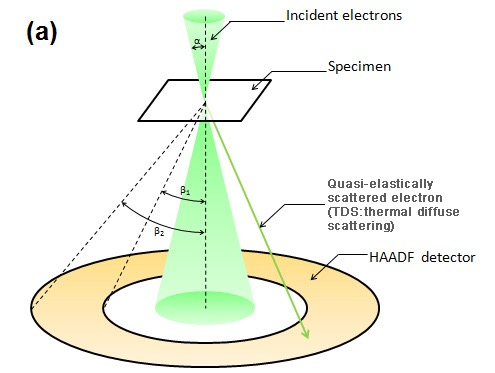

In [34]:
if not local:
    !wget https://www.dropbox.com/s/y9tunysh9duioi6/mos2_4x_ensemble_metadict.tar
    smodel, ensemble = aoi.models.load_ensemble("mos2_4x_ensemble_metadict.tar")
else:
    smodel, ensemble = aoi.models.load_ensemble("C:/Users/KoryBurns/Dropbox (ORNL)/Microscopy Data KDB/ELIT/Models/mos2_4x_ensemble_metadict.tar")

--2026-07-14 08:28:02--  https://www.dropbox.com/s/y9tunysh9duioi6/mos2_4x_ensemble_metadict.tar
Resolving www.dropbox.com (www.dropbox.com)... 162.125.1.18, 2620:100:6016:18::a27d:112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.1.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/dxuitk1je09q3vw0fsqxt/mos2_4x_ensemble_metadict.tar?rlkey=fv3rnnm03jxlizct3fxhf40or [following]
--2026-07-14 08:28:02--  https://www.dropbox.com/scl/fi/dxuitk1je09q3vw0fsqxt/mos2_4x_ensemble_metadict.tar?rlkey=fv3rnnm03jxlizct3fxhf40or
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc654bb5c5d2253151ea95c288de.dl.dropboxusercontent.com/cd/0/inline/DEPEUh6sEbUqi6ye6O7MZiU7ddci6O2Iu3YbVbXNwU2KUvWtsDF9afy4U7AS2dnyYcXhHdFjkkeOfNb6Mp8oIDpclYytM1UA2-3l5krDntM1r4P7u7L9XJ26KN4WVOAx35SQIpmyFSwa9QoQ1iKX7cDL/file# [following]
--2026-07-14 08:28:02--  https://uc654bb5c5d225315

/usr/local/lib/python3.12/dist-packages/atomai/trainers/trainer.py:667: UserWarning: No GPU found. The training can be EXTREMELY slow
  warnings.warn(


In [35]:
num_classes = smodel.px.out_channels
num_classes

1

In [36]:
colorkey_num = {0: "dodgerblue",
            1: 'yellow',
            2: 'mediumseagreen',
            3: "blueviolet",
            4: "pink",
            5 : "darkorange",
            6 : 'r'}

sizekey_num  = {0: 25,
            1 : 25,
           2: 25,
            # "S1" : 50,
           3 : 35,
            4 : 75,
            5 : 25}

In [11]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [24]:
f1, f2 = "/content/gdrive/MyDrive/Images/Numpy-TMD/2H-MoS2.npy", "/content/gdrive/MyDrive/Images/Numpy-TMD/2H-MoS2.json"
test01 = np.load(f1)

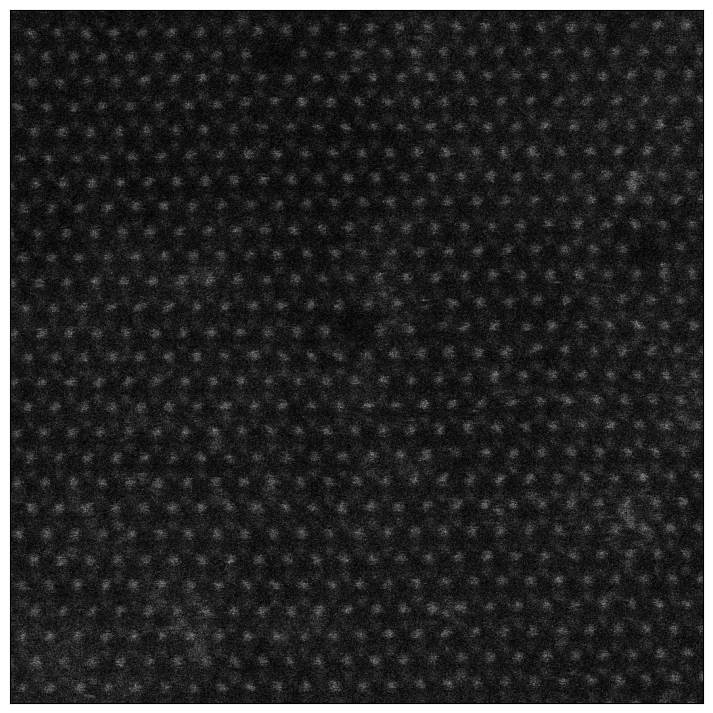

In [42]:
plt.figure(figsize=(9,9))
plt.xticks([])
plt.yticks([])
plt.imshow(test01, cmap = 'grey')

In [43]:
meta   = json.load(open(f2,'r'))
pxsize = meta["spatial_calibrations"][-1]['scale']
print(pxsize)

FOV_nm = pxsize*test01.shape[0]
print(FOV_nm)

0.0078125
8.0


## For more info on the types of models we run, see here: https://atomai.readthedocs.io/en/latest/atomai_models.html

In [44]:
###################################################
########## Model prediction parameters ############
###################################################
######### generally dont need to change much - possibly just model #########

px2ang      = 0.085  #  <---- I'm setting it to this because the model was trained using this pxsize (or close to it)
powerfactor = 1
model_num   = -1     #  <---- negative 1 here means just do all models.
##########################################
FOV_nm_test = FOV_nm
img = np.copy(test01)

# Prepare the image (rescale to appropriate physical pixel size and such)
imgdata = img_transform(test01, FOV_nm_test, px2ang, powerfactor)
ratio = img.shape[0]/imgdata.shape[0]
# Load then predict image + coordinates (coordinates are only atoms, not classes, at this point)
if model_num == -1 or model_num == 'all':
    for mn in range(len(ensemble)):
        smodel.load_state_dict(ensemble[mn])
        decoded_imgs, coordinates = aoi.predictors.SegPredictor(smodel, use_gpu=True, norm = True).run(imgdata)

        # Ensure the prediction was good:
        f,(ax1,ax2) = plt.subplots(1,2,figsize=(14,7))
        ax1.imshow(img, cmap = 'gray')
        ax2.imshow(decoded_imgs.squeeze())
        ax1.scatter(coordinates[0][:,1]*ratio, coordinates[0][:,0]*ratio, c='r', ec = 'k', s = 30)
        plt.suptitle(f"Model {mn}")
        print(f"model {mn} gives {len(coordinates[0])} coordinates")
else:
    # Ensure the prediction was good:
    smodel.load_state_dict(ensemble[model_num])
    decoded_imgs, coordinates = aoi.predictors.SegPredictor(smodel, use_gpu=True, norm = True).run(imgdata)
    f,(ax1,ax2) = plt.subplots(1,2,figsize=(14,7))
    ax1.imshow(img, cmap = 'gray')
    ax2.imshow(decoded_imgs.squeeze())
    ax1.scatter(coordinates[0][:,1]*ratio, coordinates[0][:,0]*ratio, c='r', ec = 'k', s = 30)

Output hidden; open in https://colab.research.google.com to view.

In [45]:
coordinate_threshold = 0.5

'''
You may have to adjust the coordinate_threshold to be super low (usually it's 0.5) to detect the impurities.
the network is basically thinking:

"well, there might be something there but I never really encountered it in training, so...
if you REALLY want it to be a coordinate I can do that, but you better tell me"

and that's what we do here, we tell it! by dropping that threshold away from its default value.

'''
###################################################
########## Model prediction parameters ############
###################################################
######### generally dont need to change much - possibly just model #########
# 0.0078125
px2ang      = 0.085
powerfactor = 1
model_num   = 7
##########################################

img = np.copy(test01)
# FOV_nm = SCALES[ii]*IMAGES[ii].shape[0]

# Prepare the image (rescale to appropriate physical pixel size and such)
imgdata = img_transform(test01, FOV_nm_test, px2ang, powerfactor)
ratio = img.shape[0]/imgdata.shape[0]
# Load then predict image + coordinates (coordinates are only atoms, not classes, at this point)
if model_num == -1 or model_num == 'all':
    for mn in range(len(ensemble)):
        smodel.load_state_dict(ensemble[mn])
        decoded_imgs, coordinates = aoi.predictors.SegPredictor(smodel, use_gpu=True, norm = True).run(imgdata)

        # Ensure the prediction was good:
        f,(ax1,ax2) = plt.subplots(1,2,figsize=(14,7))
        ax1.imshow(img, cmap = 'gray')
        ax2.imshow(decoded_imgs.squeeze())
        ax1.scatter(coordinates[0][:,1]*ratio, coordinates[0][:,0]*ratio, c='r', ec = 'k', s = 30)
        plt.suptitle(f"Model {mn}")
        print(f"model {mn} gives {len(coordinates[0])} coordinates")
else:
    # Ensure the prediction was good:
    smodel.load_state_dict(ensemble[model_num])
    decoded_imgs, coordinates = aoi.predictors.SegPredictor(smodel, use_gpu=True, norm = True, thresh = coordinate_threshold).run(imgdata)
    f,(ax1,ax2) = plt.subplots(1,2,figsize=(28,12))
    ax1.imshow(img, cmap = 'gray')
    ax2.imshow(decoded_imgs.squeeze())
    ax1.scatter(coordinates[0][:,1]*ratio, coordinates[0][:,0]*ratio, c='r', ec = 'k', s = 30)

print(len(coordinates[0]))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
'''
this function is the one that takes all UNCLASSIFIED coordinates and sorts them into various classes.
this serves simply to LABEL things appropriately.

if there are different classes, then our output "newcoords" should reflect that.
so, the function may need to be modified

however, since this is a TMD, many of the same features show up...!
'''

'\nthis function is the one that takes all UNCLASSIFIED coordinates and sorts them into various classes.\nthis serves simply to LABEL things appropriately.\n\nif there are different classes, then our output "newcoords" should reflect that.\nso, the function may need to be modified\n\nhowever, since this is a TMD, many of the same features show up...!\n'

window size is: 35 px

GMM components


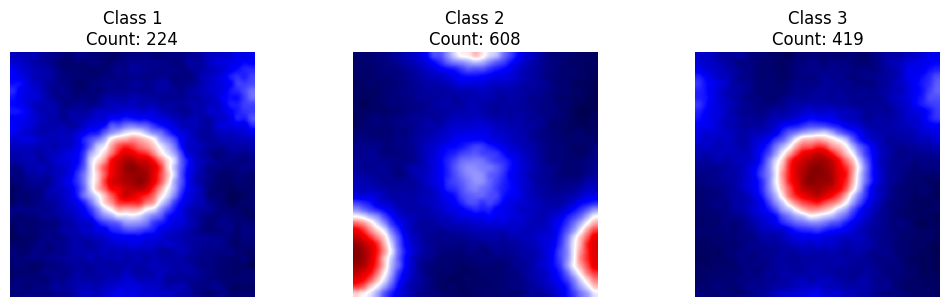

class mean differences: c01: 0.1462475210428238, c02: 0.02545049786567688, c12: 0.12079702317714691
Looks like there indeed are 3 classes


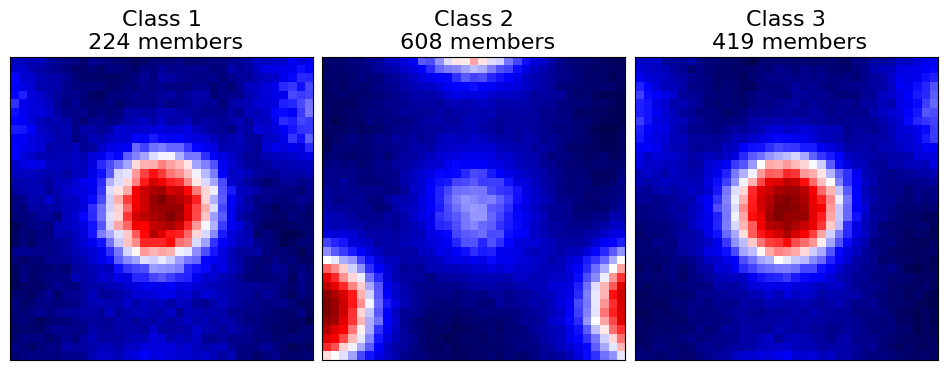

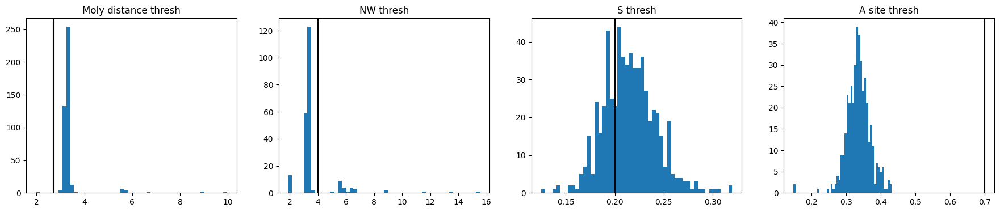

In [29]:
newcoords = MoS2_split_all(coordinates, imgdata, FOV_nm,
                           SVL_angstroms = 2.7,
                           NW_angstroms = 4,
                           A_site_intensity = 0.7,
                           A_site_sub = "bright",
                           S_intensity = 0.2,
                           plot = True,
                           filter_contamination = False)

418  Mo_reg
001  Mo_svl
430  S2
178  S1
000  Mo_sub
197  NW
027  contamination


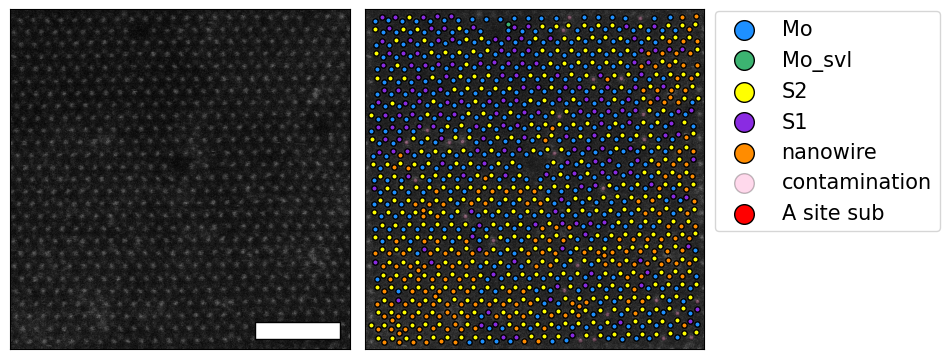

In [30]:
plot_mos2_coords(img, imgdata, newcoords, FOV_nm,
                 scalebar_length_nm = 2, lw_ratio = 5,
                 figsize_scaler = 0.6)

In [ ]:
newcoords.keys()

dict_keys(['Mo_reg', 'Mo_svl', 'S2', 'S1', 'Mo_sub', 'NW', 'contamination'])

window size is: 35 px

GMM components


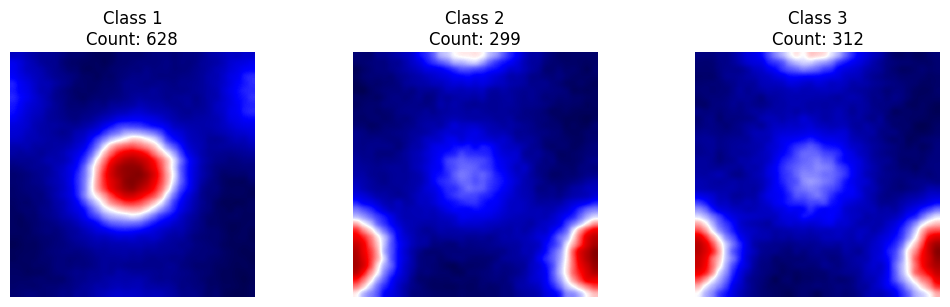

class mean differences: c01: 0.16501915454864502, c02: 0.13371166586875916, c12: 0.031307488679885864
Looks like there indeed are 3 classes


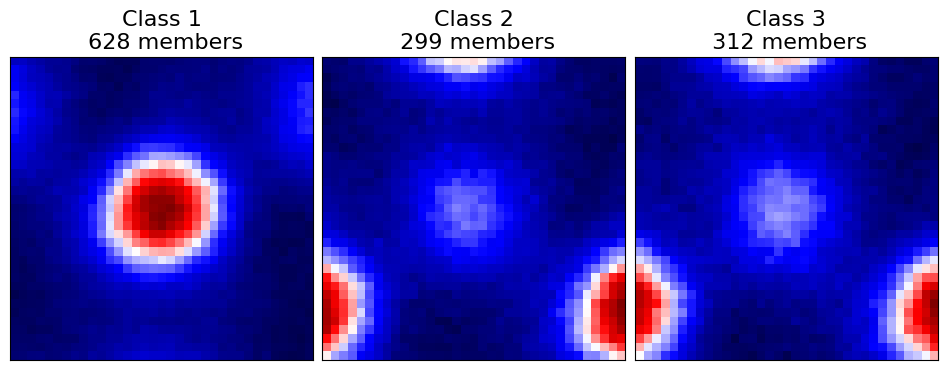

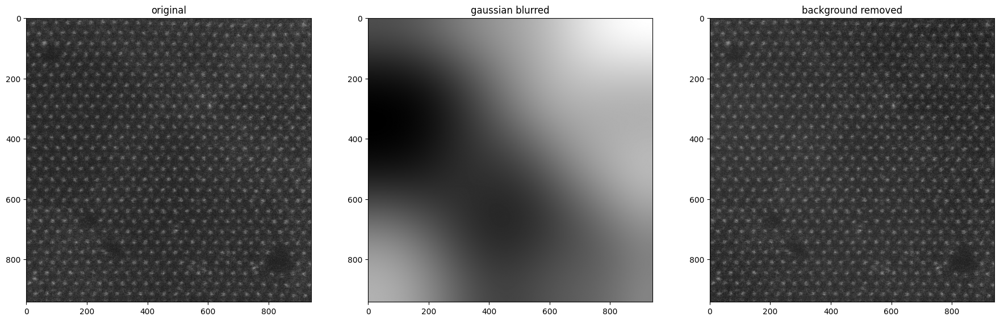

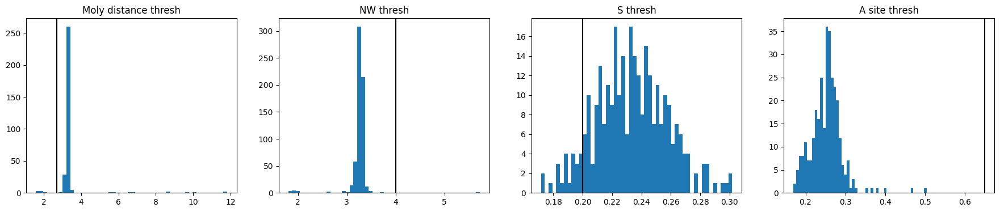

In [ ]:
newcoords = MoS2_split_all(coordinates, imgdata, FOV_nm,
                           SVL_angstroms = 2.7,
                           NW_angstroms = 4,
                           A_site_intensity = 0.65,
                           A_site_sub = "bright",
                           S_intensity = 0.2,
                           plot = True,
                           filter_contamination = True, scaling_factor = 0.22)

305  Mo_reg
007  Mo_svl
276  S2
023  S1
000  Mo_sub
627  NW
001  contamination


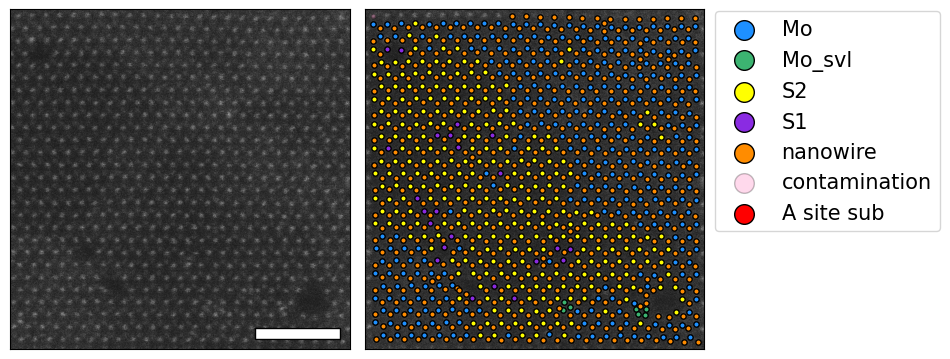

In [ ]:
plot_mos2_coords(img, imgdata, newcoords, FOV_nm,
                 scalebar_length_nm = 2, lw_ratio = 8,
                 figsize_scaler = 0.6)

# Retraining time

* once satisfied with the classification, we use this labeled data for retraining.
* Typically we need many hundreds or thousands of training images, so we artificially generate that from a handful of these experimental images
* If we were to start fresh with simulated images instead, we would do a similar thing, but also include a few examples of noise on the images. We don't really need to do that here since the images are already from experiment and therefore have the exact noise encountered anyway.

In [ ]:
'''
let's say this one image is enough for training...

(usually we'd use a number of them, something like 10 big-ish images)
'''

"\nlet's say this one image is enough for training...\n\n(usually we'd use a number of them, something like 10 big-ish images)\n"

In [ ]:
print(len(newcoords.keys()))
newcoords.keys()

7


dict_keys(['Mo_reg', 'Mo_svl', 'S2', 'S1', 'Mo_sub', 'NW', 'contamination'])

In [ ]:
frame = 0

all_coords = {}
all_images = {}

all_coords[frame] = newcoords
all_images[frame] = imgdata

In [ ]:
# assign an integer value for each class (atomai format)

classdict = {'Mo_reg' : 0, 'S2'  : 1, 'Mo_svl' : 2, 'NW' : 3, 'Mo_sub' : 4, 'S1' : 5, 'contamination' : 6}
coords_aoi_all = {}

for mm in range(len(all_coords)):
    combined = np.empty((0,3))
    for key,val in newcoords.items():
        combined = np.append(combined, np.concatenate((all_coords[mm][key][:,:2], np.full(len(all_coords[mm][key]), classdict[key]).reshape(-1,1)),axis=1))
        coords_aoi_all[mm] = combined.reshape(-1,3)

In [ ]:
coords_aoi_all[0]

array([[ 19.52054795, 871.97260274,   0.        ],
       [ 22.08333333, 697.52380952,   0.        ],
       [ 21.32307692, 740.83076923,   0.        ],
       ...,
       [923.29885057, 701.03448276,   3.        ],
       [710.80833333, 902.91666667,   6.        ],
       [919.8173913 , 919.9826087 ,   6.        ]])

In [ ]:
'''
this step is not necessary if all images are the same size (pixel size, that is)
'''


# For ease, let's make them all the same size so that we can just rotate them all at once. Otherwise annoying..
# Down sample or upsample? hmm.
# Might be safer to downsample
# but we'll get more pixels (easier to make "patches") if we upsample. Shouldn't be too crazy ..... !

# We have to do the same to the coordinates, too!

#################

# imsize = []
# coords_new = {}
# for ii in range(len(images_good)):
#     imsize.append(images_good[ii].shape[0])
# maxsize = np.max(np.asarray(imsize))
# # maxsize = np.max(imsize)

# images_new = np.zeros((len(images_good), maxsize, maxsize))
# for ii in range(len(images_good)):
#     if not images_good[ii].shape[0] == maxsize:
#         images_new[ii] = aoi.utils.cv_resize(images_good[ii], (maxsize, maxsize))
#         factor = maxsize / images_good[ii].shape[0]
#         coords_new[ii] = coords_aoi_all[ii] * [factor, factor, 1]  # i.e., rescale the coords, but don't touch the class value
#     else:
#         images_new[ii] = images_good[ii]
#         coords_new[ii] = coords_aoi_all[ii]


images_new = all_images
coords_new = coords_aoi_all

In [ ]:
angle_increment = 10

'''
Rotate them all a bit to get some angular variety going for generalizing to different experimental conditions
'''

def rotate_points(origin, points, angle, limits = [0,512]):  # ARRAY OF POINTS
    ox, oy = origin
    points = points[:,:2]
    lowerlimit, upperlimit = limits[0], limits[1]
    rotated = np.zeros((points.shape[0], points.shape[1]))
    for ii in range(points.shape[0]):
        x, y = points[ii]
        qx = ox + np.cos(np.deg2rad(angle)) * (x - ox) + np.sin(np.deg2rad(angle)) * (y - oy)
        qy = oy + -np.sin(np.deg2rad(angle)) * (x - ox) + np.cos(np.deg2rad(angle)) * (y - oy)

        if (qx < lowerlimit) or (qy < lowerlimit) or (qx > upperlimit) or (qy > upperlimit):
            pass
        else:
            rotated[ii] = qx,qy
    return rotated


training_image_r_ALL = {}
coords_r_all         = {}

for kk in range(len(images_new)):

    base_img = np.copy(images_new[kk])
    classes  = coords_new[kk][:,2]

    training_image_r = []
    # training_mask_r = []
    coords_r = []

    origin  = tuple(np.array(base_img.shape[1::-1]) / 2)

    for a in range(0, 180, angle_increment):
        training_image_r.append(aoi.utils.cv_rotate(base_img, -a))
        # training_mask_r.append(np.around(aoi.utils.cv_rotate(pred.squeeze(), -a)))
        # coords_r.append(rotate_points(origin, coords_aoi, a, [0, pred.squeeze().shape[1]]))
        rotated_coords = rotate_points(origin, coords_new[kk], a, limits = [0, base_img.shape[0] - 10])
        rotated_coords = np.concatenate((rotated_coords, classes.reshape(-1,1)),axis=1)  # add back the class channel
        coords_r.append(rotated_coords)

    training_image_r = np.array(training_image_r)
    # training_mask_r = np.array(training_mask_r)
    coords_r = np.array(coords_r)

    training_image_r_ALL[kk] = training_image_r
    coords_r_all[kk]         = coords_r

In [ ]:
colorkey_num

{0: 'dodgerblue',
 1: 'yellow',
 2: 'mediumseagreen',
 3: 'blueviolet',
 4: 'pink',
 5: 'darkorange',
 6: 'r'}

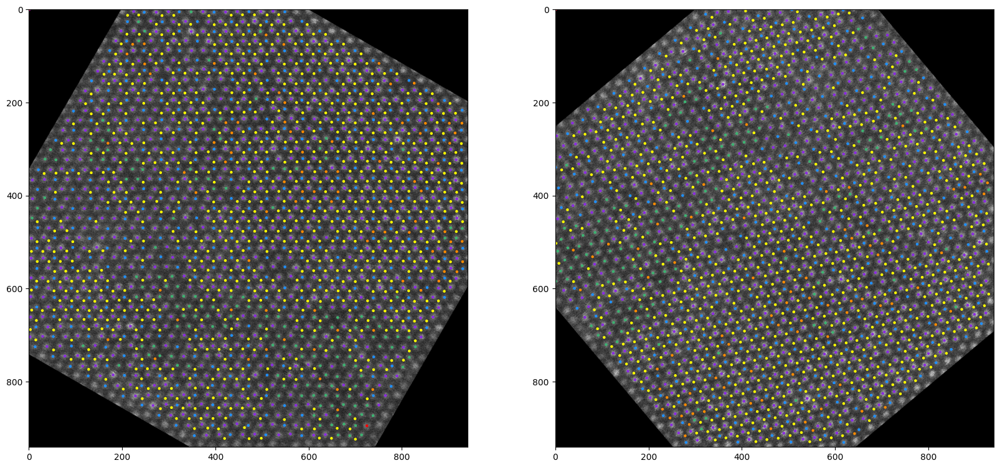

In [ ]:
parentimagenumber = 0

frame1 = 3
frame2 = 14

mapped_colors1 = np.vectorize(colorkey_num.get)(coords_r_all[parentimagenumber][frame1][:,2])
mapped_colors2 = np.vectorize(colorkey_num.get)(coords_r_all[parentimagenumber][frame2][:,2])
f,(ax1,ax2) = plt.subplots(1,2,figsize=(20,10))

ax1.imshow(training_image_r_ALL[parentimagenumber][frame1], cmap = 'gray')
ax1.scatter(coords_r_all[parentimagenumber][frame1][:,1], coords_r_all[parentimagenumber][frame1][:,0], c=mapped_colors1, s= 5)

ax2.imshow(training_image_r_ALL[parentimagenumber][frame2], cmap = 'gray')
ax2.scatter(coords_r_all[parentimagenumber][frame2][:,1], coords_r_all[parentimagenumber][frame2][:,0], c=mapped_colors2, s= 5)

In [ ]:
# Create multiclass lattice masks from all of these

In [ ]:
edge_removal = 10         # Pixels
training_mask_r_ALL = {}
coords_final_ALL    = {}

# n_classes = 3
# training_mask_r = {}

for s in range(len(training_image_r_ALL)):


    coords_final = {}

    # training_mask_r = np.zeros((training_image_r_ALL[s].shape[0], training_image_r_ALL[s].shape[1], training_image_r_ALL[s].shape[2], n_classes))
    training_mask_r = {}
    # for kk in range(len(training_mask_r)):
    for kk in range(len(training_image_r)):
        coordinates_r = aoi.utils.remove_edge_coord(coords_r_all[s][kk], (training_image_r_ALL[s][kk].shape[0], training_image_r_ALL[s][kk].shape[1]), edge_removal)
        coords_final[kk] = coordinates_r # + [-1,-1,0]                                                                                                 #[1,1,0] # need to subtract 1 only to first 2 cols (xy coords) NOT 3rd (class)!
        training_mask_r[kk] = aoi.utils.create_multiclass_lattice_mask(training_image_r_ALL[s][kk], coordinates_r, rmask=10)

    training_mask_r_ALL[s] = training_mask_r
    coords_final_ALL[s]    = coords_final

In [ ]:
print(training_image_r_ALL.keys())
print(len(training_image_r_ALL[0]))

dict_keys([0])
18


(1, 941, 941, 7)


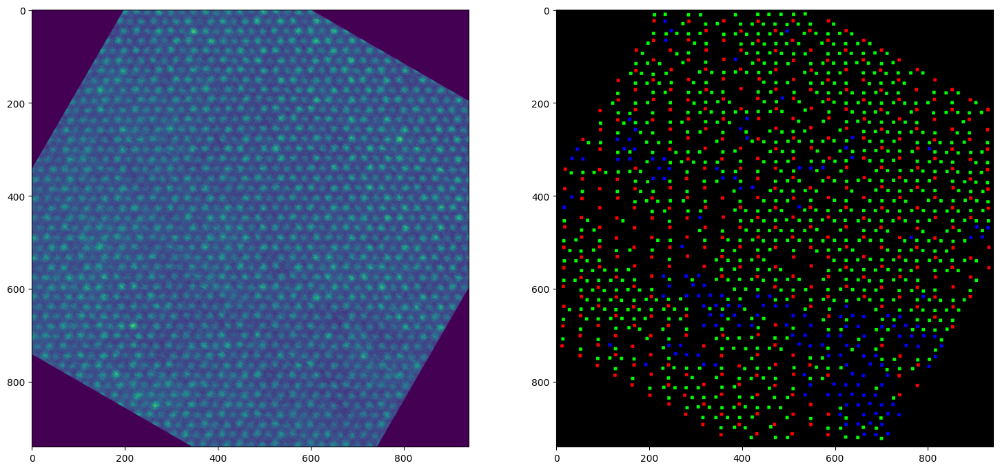

In [ ]:
'''
here are 6 channels here so we cant necessarily visualize them all at the same time. Frst 3 are sufficient to see things
'''


channel_range   = 0,3

parentimagenumber = 0
frame             = 3

f,(ax1,ax2)   = plt.subplots(1,2,figsize=(18,9))
ax1.imshow(training_image_r_ALL[parentimagenumber][frame])
ax2.imshow(training_mask_r_ALL[parentimagenumber][frame][0,:,:,channel_range[0]:channel_range[1]])

print(training_mask_r_ALL[parentimagenumber][frame].shape)

In [ ]:
'''
PATCH - I - FY !

we generally want somewhere around 1-3k total images. probably 128 x 128 are good patch sizes.
''';

In [ ]:
num_ch      = training_mask_r_ALL[parentimagenumber][frame].shape[-1]  # 6
patchsize   = 128
num_patches = 64

image_patches_all, mask_patches_all = np.empty((0,patchsize,patchsize)), np.empty((0, patchsize, patchsize, num_ch))

print(f"This will produce {num_patches*len(training_mask_r_ALL)*training_image_r_ALL[0].shape[0]} total patches. Is it sufficient or too much?")

This will produce 1152 total patches. Is it sufficient or too much?


In [ ]:
# print(training_image_r_ALL[0].shape)
# print(training_mask_r_ALL[0].shape)


In [ ]:
print(training_mask_r_ALL.keys())
print(training_mask_r_ALL[0].keys())
print(training_mask_r_ALL[0][1].shape)
# print(training_mask_r_ALL[2][1].shape)

print("")
print(training_image_r_ALL.keys())
print(training_image_r_ALL[0].shape)

dict_keys([0])
dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17])
(1, 941, 941, 7)

dict_keys([0])
(18, 941, 941)


In [ ]:
mask_patches_all = np.zeros((0,patchsize,patchsize))
image_patches_all = np.zeros((0,patchsize,patchsize))

for key,v in training_image_r_ALL.items():

    for ii in range(len(training_image_r_ALL[key])):
        image_patches_, mask_patches_ = aoi.utils.extract_patches(
        training_image_r_ALL[key][ii], training_mask_r_ALL[key][ii], patch_size=patchsize, num_patches=num_patches)


        mask_patches_sq = np.zeros(mask_patches_.shape[:-1])
        for c in range(mask_patches_.shape[-1]):
            mask_patches_sq += mask_patches_[..., c] * c

        image_patches_all = np.append(image_patches_all, image_patches_,axis = 0)
        mask_patches_all = np.append(mask_patches_all, mask_patches_sq, axis = 0)
    # mask_patches_all  = np.append(mask_patches_all, mask_patches_)

# image_patches_all = image_patches_all.reshape(-1,patchsize,patchsize)
# mask_patches_all  = mask_patches_all.reshape(-1,patchsize,patchsize)

In [ ]:
print(mask_patches_all.shape)
print(image_patches_all.shape)

(1152, 128, 128)
(1152, 128, 128)


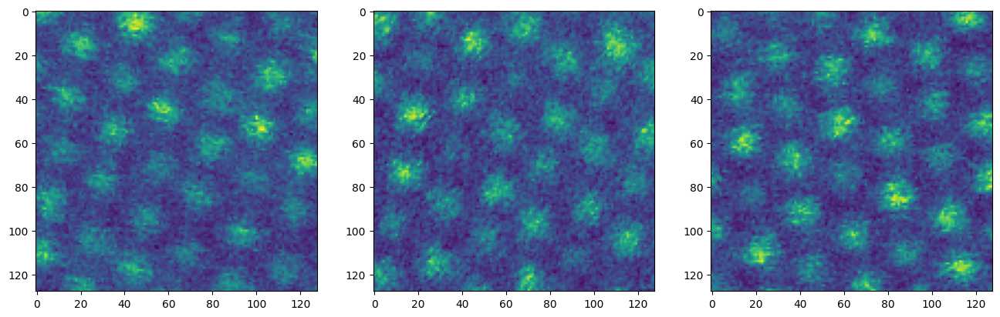

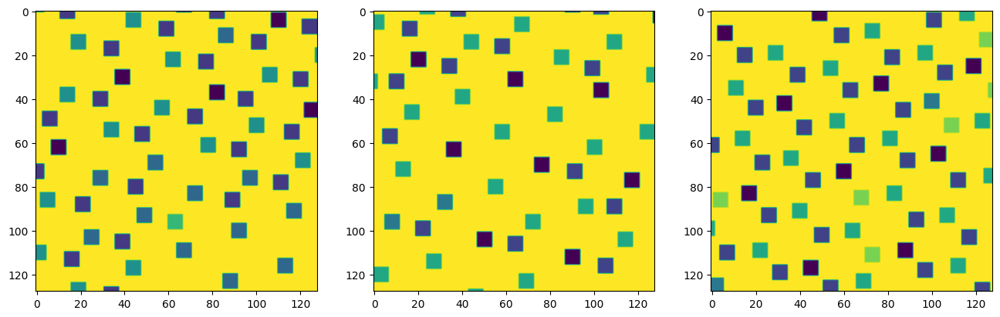

In [ ]:
fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(16,6))
ax1.imshow(image_patches_all[123])
ax2.imshow(image_patches_all[888])
ax3.imshow(image_patches_all[1111])

fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(16,6))
ax1.imshow(mask_patches_all[123])
ax2.imshow(mask_patches_all[888])
ax3.imshow(mask_patches_all[1111])

In [ ]:
aug = True  # augment by random blurring and change of image contrast (you cna also add zoom, rotation, and gauss_noise)

nchannels = training_mask_r_ALL[parentimagenumber][frame].shape[-1]

if aug:
    dt = aoi.transforms.datatransform(n_channels=nchannels, contrast=[5,10], blur=[1,2], rotation=False, zoom = 1.1)   # resize only works for INCREASING I guess (but can screw things up with interpolations), and zoom works for zooming IN ( by cropping )
    image_patches, mask_patches = dt.run(image_patches_all, mask_patches_all)

else:
    image_patches, mask_patches = image_patches_all, mask_patches_all

mask_patches.shape

(1152, 128, 128)

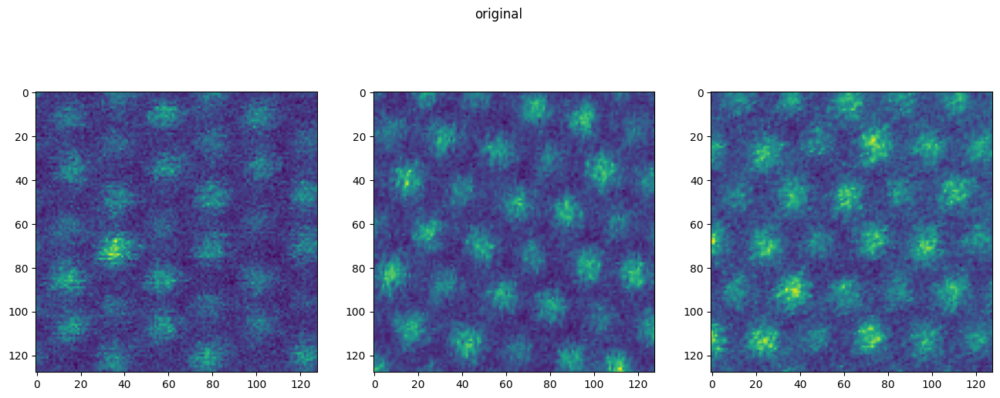

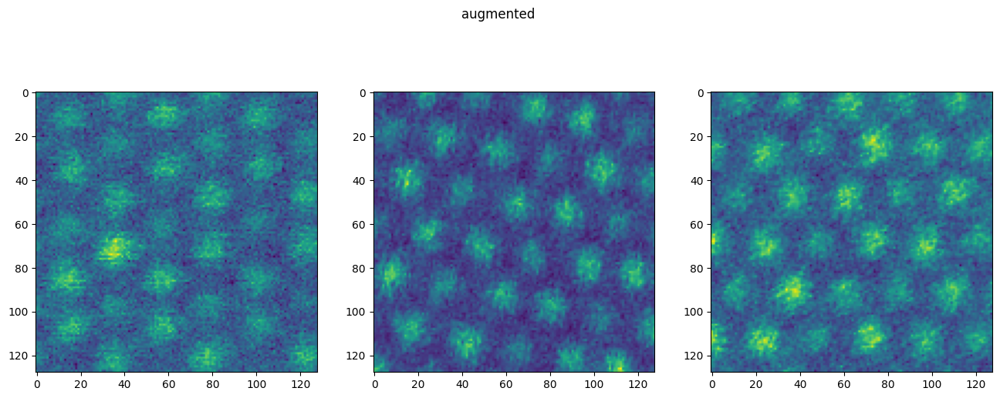

In [ ]:

fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(16,6))
plt.suptitle("original")
ax1.imshow(image_patches_all[5])
ax2.imshow(image_patches_all[640])
ax3.imshow(image_patches_all[999])

fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(16,6))
plt.suptitle("augmented")
ax1.imshow(image_patches[5].squeeze())
ax2.imshow(image_patches[640].squeeze())
ax3.imshow(image_patches[999].squeeze())


In [ ]:
'''
Save them
'''

img_patch_fname  = "image_patches_MoS2_v2"
mask_patch_fname = "mask_patches_MoS2_v2"
np.save(f"{img_patch_fname}.npy", image_patches)
np.save(f"{mask_patch_fname}.npy", mask_patches)

# Train it!
* <font color = 'darkorange'> **may need GPU version of colab for this part** </font>
* this is why I have saved the image and mask pairs in the prior cells, so that we can create the training data on a non-GPU node, then switch to a GPU node when we are ready for training (it just requires restarting runtime, so we will lose the data unless we've saved and downloaded it)
* Anyway!

In [ ]:
# mask_patches  = np.load("mos2_multiclass_mask_patches_offaxis01.npy")
# image_patches = np.load("mos2_multiclass_img_patches_offaxis01.npy")

In [ ]:
image_patches.shape

(1152, 1, 128, 128)

In [ ]:
for patch in image_patches:
    print(np.ptp(patch[0]))

0.6626769873493369
0.6800804215683313
0.643413964447714
0.7654788021312416
0.8573556401695789
0.7347141742250244
0.6616157575233396
0.7619887085268904
0.7345738449601367
0.732046095687371
0.6968458422556766
0.6965554898035627
0.6517757343705866
0.7917978309476492
0.7447327324305836
0.7416531164134383
0.7560607638800882
0.7314134492970169
0.7029017421608907
0.7309703990513725
0.8896860184500397
0.7625228383901885
0.7572816906422913
0.5923764665851652
0.6616194943039644
0.645635125129744
0.772120261708352
0.7269711446123395
0.7496033341933339
0.6548640966761773
0.6296172482927715
0.6617662050600787
0.6474176465808853
0.9354903602828355
0.7715130497597378
0.6716768563872347
0.6960115881545531
0.7265557171747494
0.6561942284431475
0.7274541270711264
0.6994572618455586
0.7504115296870162
0.7956285059915689
0.6492401282968968
0.6863710959282882
0.7380130348290715
0.6449813369196898
0.8035112533118688
0.7651254971451971
0.7271210746198201
0.6440082789177458
0.7239307186493812
0.76000702054118

In [ ]:
image_patches_normed = np.copy(image_patches)

deletion_idxes = []
for ii in range(len(image_patches_normed)):
    if np.ptp(image_patches[ii,0]) == 0:     # this might be occurring because there are literally no atoms in the entire image
        deletion_idxes.append(ii)
    else:
        image_patches_normed[ii,0] = normalize(image_patches[ii,0])

image_patches_normed = np.delete(image_patches_normed, deletion_idxes, axis = 0)
mask_patches_ = np.delete(mask_patches, deletion_idxes, axis = 0)

image_patches_normed.shape

(1152, 1, 128, 128)

In [ ]:
np.unique(mask_patches)

# This should be only 6  classes ( 0, 1, 2 )  --> background, and 5 atom classes

array([0., 1., 2., 3., 4., 5., 6.])

Training ensemble models (strategy = 'from_scratch')

Ensemble model 1
Epoch 1/1000 ... Training loss: 2.3459 ... Test loss: 1.9299 ... Train Accuracy: 0.02 ... Test Accuracy: 0.0035 ... GPU memory usage: 3859/40960
Epoch 100/1000 ... Training loss: 0.591 ... Test loss: 0.4716 ... Train Accuracy: 0.346 ... Test Accuracy: 0.3571 ... GPU memory usage: 3859/40960
Epoch 200/1000 ... Training loss: 0.3491 ... Test loss: 0.9088 ... Train Accuracy: 0.4137 ... Test Accuracy: 0.3344 ... GPU memory usage: 3859/40960
Epoch 300/1000 ... Training loss: 0.3432 ... Test loss: 0.3497 ... Train Accuracy: 0.4548 ... Test Accuracy: 0.4134 ... GPU memory usage: 3859/40960
Epoch 400/1000 ... Training loss: 0.2456 ... Test loss: 0.2635 ... Train Accuracy: 0.4936 ... Test Accuracy: 0.4871 ... GPU memory usage: 3859/40960
Epoch 500/1000 ... Training loss: 0.2337 ... Test loss: 0.251 ... Train Accuracy: 0.4992 ... Test Accuracy: 0.4824 ... GPU memory usage: 3859/40960
Epoch 600/1000 ... Training loss: 0.1835 .

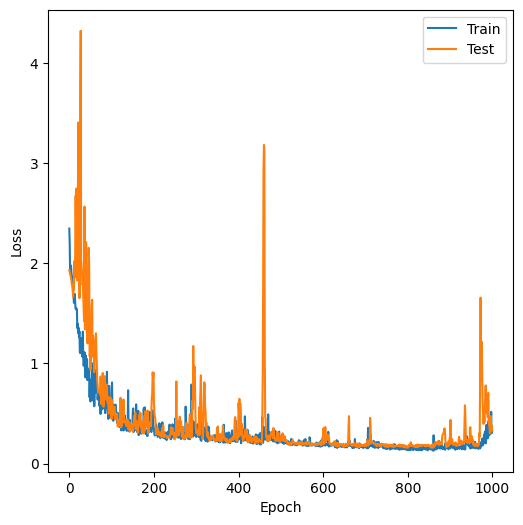


Ensemble model 2
Epoch 1/1000 ... Training loss: 2.4225 ... Test loss: 1.9495 ... Train Accuracy: 0.0122 ... Test Accuracy: 0.0035 ... GPU memory usage: 3865/40960
Epoch 100/1000 ... Training loss: 0.5324 ... Test loss: 0.6195 ... Train Accuracy: 0.3376 ... Test Accuracy: 0.3038 ... GPU memory usage: 3865/40960
Epoch 200/1000 ... Training loss: 0.3876 ... Test loss: 0.337 ... Train Accuracy: 0.4274 ... Test Accuracy: 0.4281 ... GPU memory usage: 3865/40960
Epoch 300/1000 ... Training loss: 0.257 ... Test loss: 0.6535 ... Train Accuracy: 0.4622 ... Test Accuracy: 0.4048 ... GPU memory usage: 3865/40960
Epoch 400/1000 ... Training loss: 0.3909 ... Test loss: 0.3821 ... Train Accuracy: 0.4716 ... Test Accuracy: 0.4455 ... GPU memory usage: 3865/40960
Epoch 500/1000 ... Training loss: 0.2149 ... Test loss: 0.1943 ... Train Accuracy: 0.5228 ... Test Accuracy: 0.4973 ... GPU memory usage: 3865/40960
Epoch 600/1000 ... Training loss: 0.311 ... Test loss: 0.2368 ... Train Accuracy: 0.5167 ...

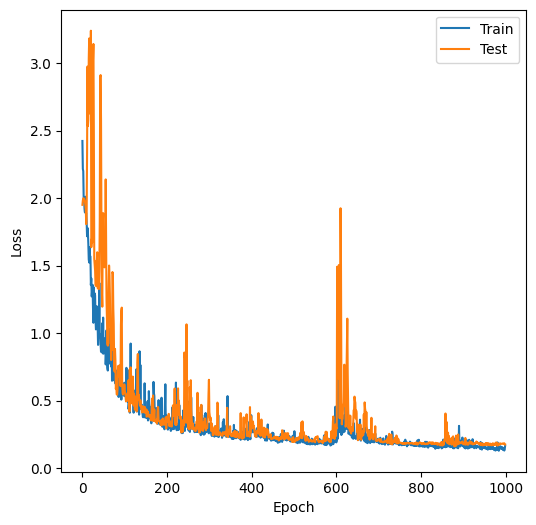


Ensemble model 3
Epoch 1/1000 ... Training loss: 2.4532 ... Test loss: 1.9263 ... Train Accuracy: 0.0124 ... Test Accuracy: 0.0031 ... GPU memory usage: 3867/40960
Epoch 100/1000 ... Training loss: 0.5242 ... Test loss: 0.7513 ... Train Accuracy: 0.3862 ... Test Accuracy: 0.3251 ... GPU memory usage: 3867/40960
Epoch 200/1000 ... Training loss: 0.3401 ... Test loss: 0.3328 ... Train Accuracy: 0.4404 ... Test Accuracy: 0.4385 ... GPU memory usage: 3867/40960
Epoch 300/1000 ... Training loss: 0.237 ... Test loss: 0.2499 ... Train Accuracy: 0.4851 ... Test Accuracy: 0.4665 ... GPU memory usage: 3867/40960
Epoch 400/1000 ... Training loss: 0.2739 ... Test loss: 0.2537 ... Train Accuracy: 0.4951 ... Test Accuracy: 0.486 ... GPU memory usage: 3867/40960
Epoch 500/1000 ... Training loss: 0.212 ... Test loss: 0.2318 ... Train Accuracy: 0.4935 ... Test Accuracy: 0.4984 ... GPU memory usage: 3867/40960
Epoch 600/1000 ... Training loss: 0.1778 ... Test loss: 0.2014 ... Train Accuracy: 0.5456 ...

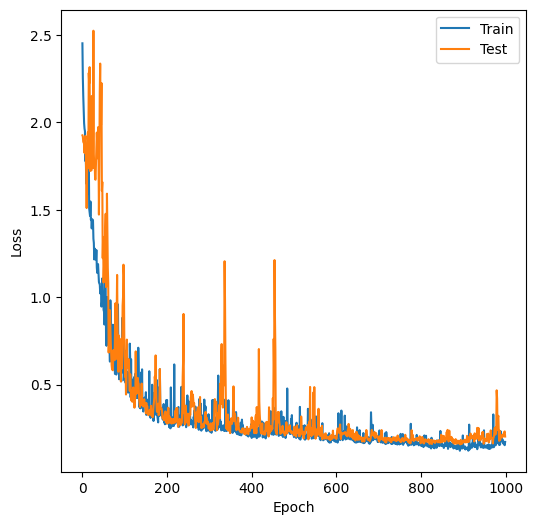


Ensemble model 4
Epoch 1/1000 ... Training loss: 2.4238 ... Test loss: 1.9271 ... Train Accuracy: 0.0256 ... Test Accuracy: 0.0036 ... GPU memory usage: 3871/40960
Epoch 100/1000 ... Training loss: 0.5384 ... Test loss: 0.9538 ... Train Accuracy: 0.3262 ... Test Accuracy: 0.2789 ... GPU memory usage: 3871/40960
Epoch 200/1000 ... Training loss: 0.3186 ... Test loss: 0.2887 ... Train Accuracy: 0.4369 ... Test Accuracy: 0.4537 ... GPU memory usage: 3871/40960
Epoch 300/1000 ... Training loss: 0.2941 ... Test loss: 0.4059 ... Train Accuracy: 0.4651 ... Test Accuracy: 0.443 ... GPU memory usage: 3871/40960
Epoch 400/1000 ... Training loss: 0.3079 ... Test loss: 0.4566 ... Train Accuracy: 0.4747 ... Test Accuracy: 0.4187 ... GPU memory usage: 3871/40960
Epoch 500/1000 ... Training loss: 0.2533 ... Test loss: 0.2001 ... Train Accuracy: 0.5033 ... Test Accuracy: 0.5128 ... GPU memory usage: 3871/40960
Epoch 600/1000 ... Training loss: 0.1731 ... Test loss: 0.1962 ... Train Accuracy: 0.5669 .

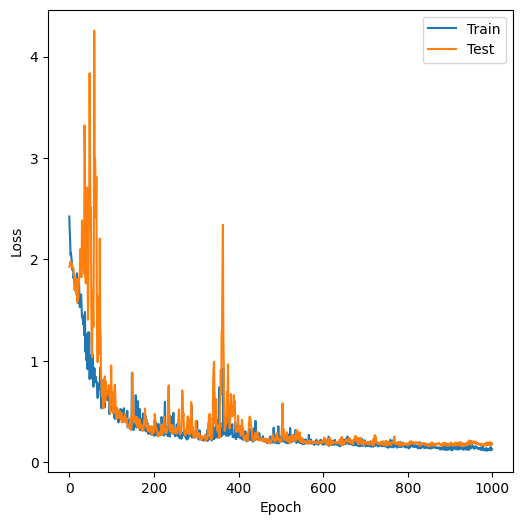


Ensemble model 5
Epoch 1/1000 ... Training loss: 2.4617 ... Test loss: 1.9584 ... Train Accuracy: 0.0199 ... Test Accuracy: 0.0036 ... GPU memory usage: 3873/40960
Epoch 100/1000 ... Training loss: 0.5634 ... Test loss: 1.021 ... Train Accuracy: 0.3239 ... Test Accuracy: 0.2553 ... GPU memory usage: 3873/40960
Epoch 200/1000 ... Training loss: 0.4761 ... Test loss: 0.4211 ... Train Accuracy: 0.3688 ... Test Accuracy: 0.3652 ... GPU memory usage: 3873/40960
Epoch 300/1000 ... Training loss: 0.2586 ... Test loss: 0.2947 ... Train Accuracy: 0.4553 ... Test Accuracy: 0.4281 ... GPU memory usage: 3873/40960
Epoch 400/1000 ... Training loss: 0.2581 ... Test loss: 0.258 ... Train Accuracy: 0.4749 ... Test Accuracy: 0.4751 ... GPU memory usage: 3873/40960
Epoch 500/1000 ... Training loss: 0.1967 ... Test loss: 0.2375 ... Train Accuracy: 0.5259 ... Test Accuracy: 0.4944 ... GPU memory usage: 3873/40960
Epoch 600/1000 ... Training loss: 0.1886 ... Test loss: 0.1922 ... Train Accuracy: 0.5464 ..

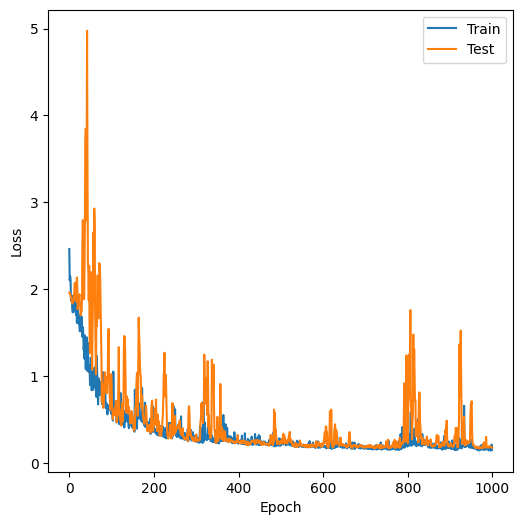


Ensemble model 6
Epoch 1/1000 ... Training loss: 2.3553 ... Test loss: 1.9804 ... Train Accuracy: 0.0398 ... Test Accuracy: 0.0035 ... GPU memory usage: 3875/40960
Epoch 100/1000 ... Training loss: 0.5882 ... Test loss: 0.4548 ... Train Accuracy: 0.3182 ... Test Accuracy: 0.3424 ... GPU memory usage: 3875/40960
Epoch 200/1000 ... Training loss: 0.3195 ... Test loss: 0.427 ... Train Accuracy: 0.3946 ... Test Accuracy: 0.3692 ... GPU memory usage: 3875/40960
Epoch 300/1000 ... Training loss: 0.239 ... Test loss: 0.2699 ... Train Accuracy: 0.4697 ... Test Accuracy: 0.4478 ... GPU memory usage: 3875/40960
Epoch 400/1000 ... Training loss: 0.2109 ... Test loss: 0.2264 ... Train Accuracy: 0.496 ... Test Accuracy: 0.4938 ... GPU memory usage: 3875/40960
Epoch 500/1000 ... Training loss: 0.1996 ... Test loss: 0.2821 ... Train Accuracy: 0.5115 ... Test Accuracy: 0.475 ... GPU memory usage: 3875/40960
Epoch 600/1000 ... Training loss: 0.1769 ... Test loss: 0.1924 ... Train Accuracy: 0.5416 ... 

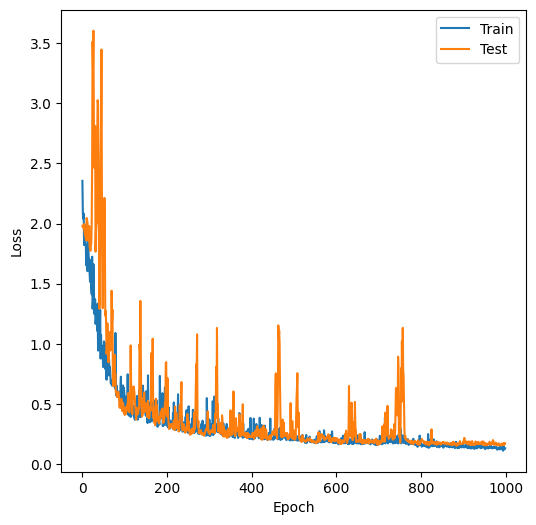


Ensemble model 7
Epoch 1/1000 ... Training loss: 2.5015 ... Test loss: 1.944 ... Train Accuracy: 0.0291 ... Test Accuracy: 0.0035 ... GPU memory usage: 3941/40960
Epoch 100/1000 ... Training loss: 0.4106 ... Test loss: 0.4565 ... Train Accuracy: 0.3773 ... Test Accuracy: 0.3724 ... GPU memory usage: 3941/40960
Epoch 200/1000 ... Training loss: 0.3747 ... Test loss: 0.5102 ... Train Accuracy: 0.4102 ... Test Accuracy: 0.3898 ... GPU memory usage: 3941/40960
Epoch 300/1000 ... Training loss: 0.5205 ... Test loss: 0.3191 ... Train Accuracy: 0.3861 ... Test Accuracy: 0.4282 ... GPU memory usage: 3941/40960
Epoch 400/1000 ... Training loss: 0.2555 ... Test loss: 0.1972 ... Train Accuracy: 0.4911 ... Test Accuracy: 0.5172 ... GPU memory usage: 3941/40960
Epoch 500/1000 ... Training loss: 0.1852 ... Test loss: 0.1971 ... Train Accuracy: 0.5366 ... Test Accuracy: 0.517 ... GPU memory usage: 3941/40960
Epoch 600/1000 ... Training loss: 0.1834 ... Test loss: 0.1945 ... Train Accuracy: 0.5513 ..

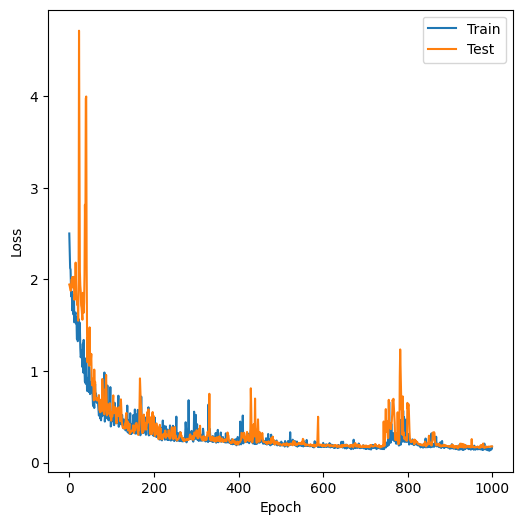


Ensemble model 8
Epoch 1/1000 ... Training loss: 2.3399 ... Test loss: 1.9802 ... Train Accuracy: 0.0313 ... Test Accuracy: 0.0036 ... GPU memory usage: 3879/40960
Epoch 100/1000 ... Training loss: 0.4629 ... Test loss: 0.8279 ... Train Accuracy: 0.3568 ... Test Accuracy: 0.2854 ... GPU memory usage: 3879/40960
Epoch 200/1000 ... Training loss: 0.2733 ... Test loss: 0.3548 ... Train Accuracy: 0.445 ... Test Accuracy: 0.4214 ... GPU memory usage: 3879/40960
Epoch 300/1000 ... Training loss: 0.2761 ... Test loss: 0.3599 ... Train Accuracy: 0.4698 ... Test Accuracy: 0.4494 ... GPU memory usage: 3879/40960
Epoch 400/1000 ... Training loss: 0.2208 ... Test loss: 0.2419 ... Train Accuracy: 0.4853 ... Test Accuracy: 0.4721 ... GPU memory usage: 3879/40960
Epoch 500/1000 ... Training loss: 0.2058 ... Test loss: 0.2198 ... Train Accuracy: 0.5312 ... Test Accuracy: 0.5158 ... GPU memory usage: 3879/40960
Epoch 600/1000 ... Training loss: 0.215 ... Test loss: 0.3281 ... Train Accuracy: 0.51 ... 

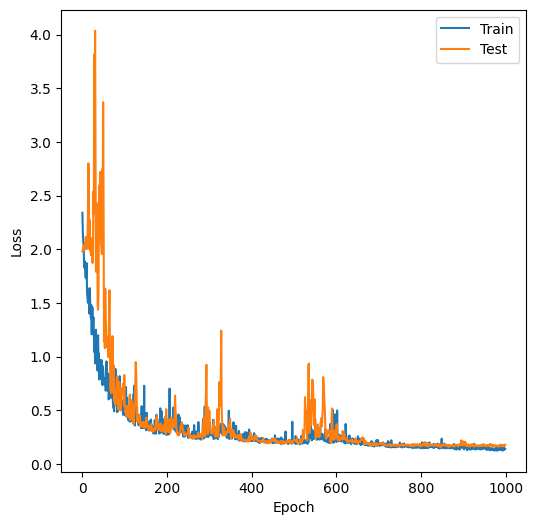


Ensemble model 9
Epoch 1/1000 ... Training loss: 2.3872 ... Test loss: 1.9489 ... Train Accuracy: 0.0197 ... Test Accuracy: 0.0035 ... GPU memory usage: 3881/40960
Epoch 100/1000 ... Training loss: 0.6862 ... Test loss: 0.4538 ... Train Accuracy: 0.3146 ... Test Accuracy: 0.3654 ... GPU memory usage: 3881/40960
Epoch 200/1000 ... Training loss: 0.3845 ... Test loss: 0.6089 ... Train Accuracy: 0.4232 ... Test Accuracy: 0.3701 ... GPU memory usage: 3881/40960
Epoch 300/1000 ... Training loss: 0.2091 ... Test loss: 0.207 ... Train Accuracy: 0.4832 ... Test Accuracy: 0.4848 ... GPU memory usage: 3881/40960
Epoch 400/1000 ... Training loss: 0.2257 ... Test loss: 0.9418 ... Train Accuracy: 0.4854 ... Test Accuracy: 0.3999 ... GPU memory usage: 3881/40960
Epoch 500/1000 ... Training loss: 0.2138 ... Test loss: 0.188 ... Train Accuracy: 0.5114 ... Test Accuracy: 0.5258 ... GPU memory usage: 3881/40960
Epoch 600/1000 ... Training loss: 0.2541 ... Test loss: 0.3398 ... Train Accuracy: 0.5051 ..

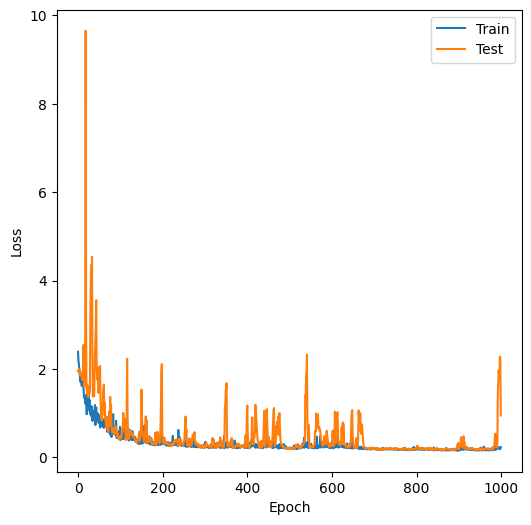


Ensemble model 10
Epoch 1/1000 ... Training loss: 2.4218 ... Test loss: 1.9618 ... Train Accuracy: 0.0139 ... Test Accuracy: 0.0031 ... GPU memory usage: 3883/40960
Epoch 100/1000 ... Training loss: 0.4818 ... Test loss: 0.502 ... Train Accuracy: 0.3551 ... Test Accuracy: 0.3515 ... GPU memory usage: 3883/40960
Epoch 200/1000 ... Training loss: 0.254 ... Test loss: 0.3559 ... Train Accuracy: 0.462 ... Test Accuracy: 0.4388 ... GPU memory usage: 3883/40960
Epoch 300/1000 ... Training loss: 0.2746 ... Test loss: 0.2936 ... Train Accuracy: 0.4565 ... Test Accuracy: 0.4357 ... GPU memory usage: 3883/40960
Epoch 400/1000 ... Training loss: 0.2957 ... Test loss: 0.2491 ... Train Accuracy: 0.4812 ... Test Accuracy: 0.4827 ... GPU memory usage: 3883/40960
Epoch 500/1000 ... Training loss: 0.18 ... Test loss: 0.2122 ... Train Accuracy: 0.5443 ... Test Accuracy: 0.5172 ... GPU memory usage: 3883/40960
Epoch 600/1000 ... Training loss: 0.2311 ... Test loss: 0.1827 ... Train Accuracy: 0.5415 ... 

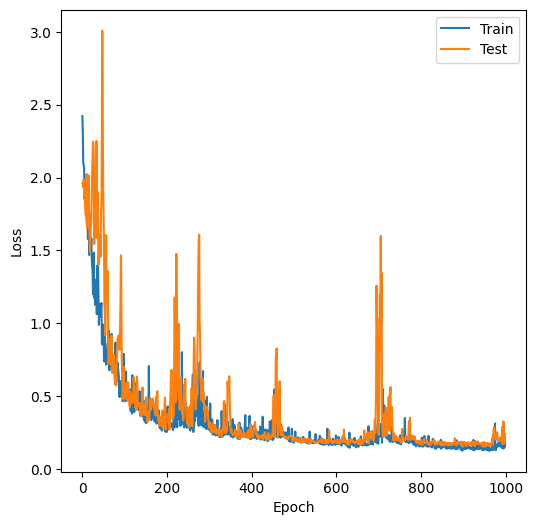

In [ ]:
ens_fname           = "mos2_v2"

num_classes         = 7
n_models            = 10     # Usually set to 6 at minimum, usually about 10 is good. 1 is just for testing.
training_cycles     = 1000   # usually set to 1000. couple hundred for testing
train_new           = True


if train_new:
  etrainer = aoi.trainers.EnsembleTrainer("Unet", nb_classes=num_classes, with_dilation=False,
                                          batch_norm=True)
  etrainer.compile_ensemble_trainer(training_cycles=training_cycles, compute_accuracy=True, swa=True, memory_alloc=0.5, filename=ens_fname)
  smodel, ensemble = etrainer.train_ensemble_from_scratch(image_patches_normed, mask_patches_, n_models=n_models, layers=[2, 3, 3, 4])

In [ ]:
'''
IoU is a good metric for knowing how well the training has done.
generally look for 0.7 or higher

note: this one shows ~0.53 which is not amazing HOWEVER, 1) I only used 200 epochs, and 2) things start to get a little messier when adding more and more classes
'''

# Test it

In [ ]:
import os
cwd = os.getcwd()
smodel, ensemble = aoi.models.load_ensemble(cwd+"//mos2_v2_ensemble_metadict.tar")

In [ ]:
f1

'/content/3R_0.npy'

In [ ]:
num_classes = smodel.px.out_channels
num_classes

7

In [ ]:
'''
we would test a different image here of course but anyway.
We need the image, and the FOV (pixel size important)
'''

testimg = test01

meta   = json.load(open(f2,'r'))
pxsize = meta["spatial_calibrations"][-1]['scale']
print(pxsize)

FOV_nm = pxsize*test01.shape[0]
print(FOV_nm)

0.0078125
8.0


In [ ]:
def decoded_squeeze(decoded_img, num_classes):

    decoded = decoded_img.squeeze()

    if num_classes > 1:
        class_thresh = 0.5  # Should be about 50% or higher for that class... Actually 50% seems to be about the best for imaging this. (both lower AND higher is not so great)
        clengths = []
        for ch in range(decoded.shape[-1]):
            clengths.append(len(np.where(decoded[:,:,ch] > class_thresh)[1]))
        clengths = np.asarray(clengths)
        background_ch = clengths.argmax()  # We assume that MOST pixels are background, which should be a valid assumption.

        decoded_ = np.zeros(decoded.shape[:-1])
        for ch in range(decoded.shape[-1]):
            if not ch == background_ch:
                decoded_ += decoded[..., ch] * (ch+1)
        decoded = decoded_

    else: pass

    return decoded

(1024, 1024)
0.0078125


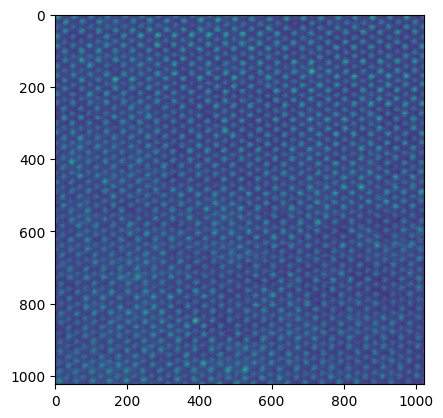

In [ ]:
'''
Note, we trained at a pixel size of 0.0078 nm per pixel (in the example)
'''


plt.imshow(testimg)
print(testimg.shape)
print(pxsize)

1024
Batch 1/1
1 image was decoded in approximately 1.0678 seconds


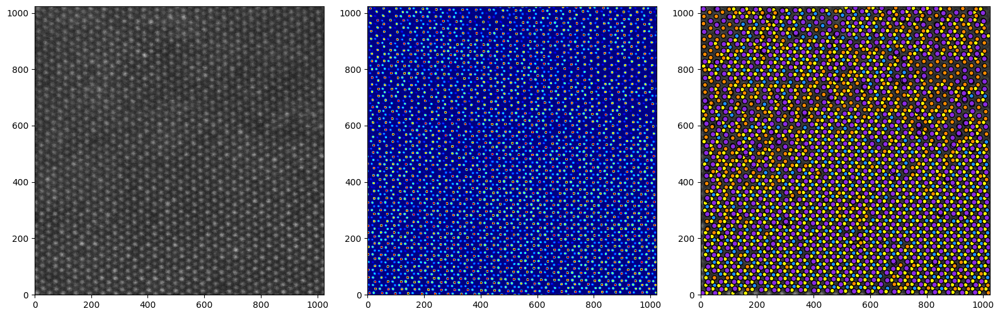

In [ ]:
img = normalize(testimg)


powerfactor = 1
model   = 4
FOV = FOV_nm

resize_dim = int(FOV/pxsize)
imgdata_r = aoi.utils.cv_resize(img, (resize_dim, resize_dim))
imgdata = normalize((imgdata_r - imgdata_r.min())**powerfactor)

print(resize_dim)

smodel.load_state_dict(ensemble[model])
decoded_imgs, coordinates = aoi.predictors.SegPredictor(smodel, use_gpu=False, norm = True).run(imgdata)
decoded = decoded_squeeze(decoded_imgs, num_classes)

fig, axs = plt.subplots(1, 3, figsize=(16, 8))
axs[0].imshow(imgdata, cmap='gray', origin="lower")

# axs[1].imshow(decoded_imgs[0,:,:,:3], origin = 'lower')
axs[1].imshow(decoded, origin = 'lower', cmap = 'jet')
axs[2].imshow(imgdata, cmap = 'gray', origin = 'lower')


mapped_colors = np.vectorize(colorkey_num.get)(coordinates[0][:,2])
mapped_sizes = np.vectorize(sizekey_num.get)(coordinates[0][:,2])
axs[2].scatter(coordinates[0][:,1], coordinates[0][:,0], c = mapped_colors, s=mapped_sizes, ec='k')

plt.tight_layout()

In [ ]:
colorkey_num = {0: "dodgerblue",
                1: "yellow",
                2: "darkorange",
                3: "blueviolet",
                4: "mediumseagreen",
                5: "pink",
                6: "r"}


In [ ]:
# colorkey_num

In [ ]:
mapped_colors = np.vectorize(colorkey_num.get)(coordinates[0][:,2])
plt.figure(figsize=(15,15))
plt.imshow(testimg, cmap = 'gray')
plt.scatter(coordinates[0][:,1], coordinates[0][:,0], c=mapped_colors, s = 70, alpha=0.85, ec='k')

Output hidden; open in https://colab.research.google.com to view.

* hey works pretty well I think!
* in practice, for use on a microscope, you'd use one of the best models in the ensemble (e.g., model #3 of 10)
* offline use, we should make use of the entire ensemble to predict (takes  a little longer, but we get model uncertainty which can be very useful for semi-quantifying our confidence)


In [ ]:
'''
final note:

1. generally the nuber of defect classes should be roughly the same for training data.
   - i.e., lets say we have a total of 5000 atoms.
   - if there are only 2 defects in the parent image, they will only rarely show up in the training data, hence it will be difficult to detect them with the network
   - we need to *artificially** make this more apparent (it doesn't matter that it is a more rare event to find such defects, the training just needs to be able to recognize it)

   - talk to me if you want to do this, there are a few things that can be tried here

2. with that in mind, it might be better to train with only 3 classes (a, b, c sites) and do any refinement of those afterwards.

''';